# Predicción de diabetes mediante técnicas de minería de datos aplicadas a indicadores clínicos

### Tercer corte — Notebook de trabajo (Actividad 1: integración y despliegue en Streamlit)

**Universidad de la Costa (CUC)** · Departamento de Ciencias de la Computación y Electrónica
**Asignatura:** Data Mining — **Docente:** José Escorcia-Gutiérrez, Ph.D.

**Integrantes:** Santiago Andrés Lozano

**Tipo de proyecto:** Clasificación (variable objetivo binaria: presencia o ausencia de diabetes)

---

### Pregunta que se busca responder

> ¿Qué indicadores clínicos y demográficos permiten predecir el diagnóstico de diabetes en esta
> población, y qué modelo de clasificación logra la mejor detección de los casos positivos?

La segunda mitad de la pregunta es deliberada. En un problema de tamizaje no basta con acertar
mucho en total: interesa sobre todo no dejar pasar a las pacientes que sí tienen la enfermedad.
Esa precisión en el planteamiento es la que después nos obliga a elegir el modelo con un criterio
distinto al de la exactitud global.

### Dataset

| | |
|---|---|
| **Nombre** | Pima Indians Diabetes Database |
| **Fuente original** | National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK), distribuido por el UCI Machine Learning Repository |
| **Enlace de descarga** | https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database |
| **Copia pública usada en el notebook** | https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv |
| **Tamaño original** | 768 registros × 9 columnas |
| **Variable objetivo** | `outcome` (1 = diagnosticada con diabetes, 0 = no) |

---

Este cuaderno continúa el del primer avance. Se conservan la carga, la descripción del conjunto,
el diagnóstico de calidad y las decisiones de limpieza que ya habíamos documentado, y sobre esa
base se agregan el análisis exploratorio ampliado, el entrenamiento de los modelos y su
evaluación. Las gráficas siguen en escala de grises para que el documento se imprima sin perder
legibilidad.

---

**Qué agrega el tercer corte.** Las secciones 1 a 7 son las del segundo avance y se conservan sin cambios, porque esta entrega no repite el análisis exploratorio: parte de él. A partir de la **sección 8** empieza el trabajo de este corte, que revisa el rendimiento del modelo, lo optimiza, lo serializa con `joblib` y deja listos los archivos de la aplicación desplegada en Streamlit Community Cloud.

| | |
|---|---|
| **Aplicación** | (enlace público de Streamlit) |
| **Repositorio** | (enlace público de GitHub) |

## 1. Continuidad con el primer avance

### 1.1. Cambios frente a la primera entrega y su justificación

Hay tres cambios respecto a lo entregado en el primer corte. El primero es de método y es el
más importante de los tres.

**1. La imputación se trasladó al interior del pipeline de modelado.** En el primer avance
rellenamos los valores faltantes con la mediana calculada sobre el conjunto completo y, en ese
mismo cuaderno, dejamos anotado que eso había que corregirlo al momento de entrenar. La razón es
que la mediana global se calcula usando también los registros que luego harán de prueba, de modo
que el modelo recibe información del conjunto de evaluación antes de ser evaluado y las métricas
salen infladas. Esa es la definición de una fuga de información. En esta entrega los faltantes quedan
declarados como nulos y el imputador se ajusta únicamente con los datos de entrenamiento, dentro
de un `Pipeline` de scikit-learn. Como consecuencia, el análisis exploratorio de esta entrega
también trabaja con los nulos explícitos en lugar del conjunto imputado, lo que elimina de paso
el pico artificial que la imputación provocaba en los histogramas.

**2. Se corrigió el año de una referencia.** El artículo de Ariza-Colpas y colaboradores en
*Current Medical Imaging* estaba citado como 2022 y el año correcto del número es 2023; salió en
línea en enero de 2022, que fue el origen de la confusión.

**3. Se agregó una sexta referencia del Departamento.** Se incorporó Ariza-Colpas et al. (2022),
publicado en *Sensors*, cuya portada registra explícitamente la afiliación al Departamento de
Ciencias de la Computación y Electrónica de la Universidad de la Costa.

No hubo cambio de dataset, ni de pregunta, ni de variable objetivo, ni se excluyó ninguna
variable respecto a lo planteado en el primer avance.

In [1]:
# Librerías. A diferencia del primer avance, aquí sí entra scikit-learn porque
# esta entrega incluye entrenamiento y evaluación de modelos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score,
                             precision_score, recall_score, f1_score)

# Semilla única para todo el cuaderno: así cualquiera que lo ejecute obtiene
# exactamente los mismos números que aparecen en el informe.
SEMILLA = 42

# Estilo en escala de grises
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "0.88"
plt.rcParams["grid.linewidth"] = 0.7
plt.rcParams["axes.edgecolor"] = "0.25"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["font.size"] = 10
plt.rcParams["figure.facecolor"] = "white"

GRIS = "0.65"
GRIS_OSCURO = "0.35"
NEGRO = "0.15"

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 25)

print(f"Semilla fijada en {SEMILLA} para todo el cuaderno.")

Semilla fijada en 42 para todo el cuaderno.


### 1.2. Carga del dataset y exploración inicial

In [2]:
# Carga. Si el CSV está subido al entorno se usa el archivo local; si no, se descarga
# de la copia pública, para que el cuaderno corra en Colab sin pasos previos.
URL = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

try:
    df = pd.read_csv("diabetes.csv")
    print("Cargado desde archivo local.")
except FileNotFoundError:
    df = pd.read_csv(URL)
    print("Cargado desde la URL pública.")

print(f"Registros (filas): {df.shape[0]}")
print(f"Variables (columnas): {df.shape[1]}")
df.head(10)

Cargado desde archivo local.
Registros (filas): 768
Variables (columnas): 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [3]:
# Nombres de columna en snake_case, como se definió en el primer avance.
df = df.rename(columns={
    "Pregnancies": "pregnancies",
    "Glucose": "glucose",
    "BloodPressure": "blood_pressure",
    "SkinThickness": "skin_thickness",
    "Insulin": "insulin",
    "BMI": "bmi",
    "DiabetesPedigreeFunction": "diabetes_pedigree",
    "Age": "age",
    "Outcome": "outcome",
})

objetivo = "outcome"
predictoras = [c for c in df.columns if c != objetivo]
numericas = df[predictoras].select_dtypes(include=["int64", "float64"]).columns.tolist()
categoricas = df[predictoras].select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Variable objetivo: {objetivo}")
print(f"Numéricas ({len(numericas)}): {numericas}")
print(f"Categóricas ({len(categoricas)}): {categoricas if categoricas else 'ninguna'}")

Variable objetivo: outcome
Numéricas (8): ['pregnancies', 'glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi', 'diabetes_pedigree', 'age']
Categóricas (0): ninguna


In [4]:
# Descripción de cada variable, para dejarla a mano dentro del propio cuaderno
descripcion = pd.DataFrame({
    "variable": ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin",
                 "bmi", "diabetes_pedigree", "age", "outcome"],
    "significado": [
        "Número de embarazos de la paciente",
        "Glucosa en plasma a las 2 h de una prueba oral de tolerancia (mg/dL)",
        "Presión arterial diastólica (mm Hg)",
        "Espesor del pliegue cutáneo del tríceps (mm)",
        "Insulina sérica a las 2 h (mu U/ml)",
        "Índice de masa corporal (kg/m2)",
        "Índice de antecedente familiar de diabetes",
        "Edad en años",
        "Diagnóstico de diabetes (1 = sí, 0 = no) — VARIABLE OBJETIVO",
    ],
    "tipo": ["numérica discreta", "numérica continua", "numérica continua", "numérica continua",
             "numérica continua", "numérica continua", "numérica continua", "numérica discreta",
             "binaria"],
})
descripcion.set_index("variable")

,significado,tipo
variable,,
pregnancies,Número de embarazos de la paciente,numérica discreta
glucose,Glucosa en plasma a las 2 h de una prueba oral...,numérica continua
blood_pressure,Presión arterial diastólica (mm Hg),numérica continua
skin_thickness,Espesor del pliegue cutáneo del tríceps (mm),numérica continua
insulin,Insulina sérica a las 2 h (mu U/ml),numérica continua
bmi,Índice de masa corporal (kg/m2),numérica continua
diabetes_pedigree,Índice de antecedente familiar de diabetes,numérica continua
age,Edad en años,numérica discreta
outcome,"Diagnóstico de diabetes (1 = sí, 0 = no) — VAR...",binaria


In [5]:
# Tipos de datos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pregnancies        768 non-null    int64  
 1   glucose            768 non-null    int64  
 2   blood_pressure     768 non-null    int64  
 3   skin_thickness     768 non-null    int64  
 4   insulin            768 non-null    int64  
 5   bmi                768 non-null    float64
 6   diabetes_pedigree  768 non-null    float64
 7   age                768 non-null    int64  
 8   outcome            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
# Estadísticas descriptivas del dataset tal como viene
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
blood_pressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
skin_thickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
bmi,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
diabetes_pedigree,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


### 1.3. Diagnóstico de calidad: lo que ya habíamos encontrado

Se conserva la evidencia del primer avance. El resumen es que `isnull()` no detecta nada, pero
cinco variables clínicas usan el cero como marcador de dato ausente, cosa que se descubre al
mirar los mínimos de `describe()`.

In [7]:
# 1) Nulos explícitos y duplicados
print(f"Valores nulos declarados como NaN: {df.isnull().sum().sum()}")
print(f"Filas duplicadas completas: {df.duplicated().sum()}")
print(f"Filas únicas: {df.drop_duplicates().shape[0]} de {df.shape[0]}")

Valores nulos declarados como NaN: 0
Filas duplicadas completas: 0
Filas únicas: 768 de 768


In [8]:
# 2) Variables mal codificadas: ceros clínicamente imposibles
imposibles_cero = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]

diagnostico = pd.DataFrame({
    "ceros": (df[imposibles_cero] == 0).sum(),
    "% de la columna": ((df[imposibles_cero] == 0).mean() * 100).round(2),
})
print(diagnostico.to_string())

encubiertos = df[imposibles_cero].replace(0, np.nan).isnull().any(axis=1).sum()
print(f"\nFilas con al menos un faltante encubierto: {encubiertos} "
      f"({encubiertos / len(df) * 100:.2f} %)")

# El cero SÍ es válido en 'pregnancies' (nunca ha estado embarazada) y en 'outcome' (clase
# negativa), así que esas dos columnas quedan fuera de la corrección.
print(f"Pacientes con 0 embarazos: {(df['pregnancies'] == 0).sum()} (valor válido, no se toca)")

                ceros  % de la columna
glucose             5             0.65
blood_pressure     35             4.56
skin_thickness    227            29.56
insulin           374            48.70
bmi                11             1.43

Filas con al menos un faltante encubierto: 376 (48.96 %)
Pacientes con 0 embarazos: 111 (valor válido, no se toca)


In [9]:
# 3) Datos inconsistentes: rangos una vez descartados los ceros
revision = df[imposibles_cero].replace(0, np.nan)
pd.DataFrame({
    "mínimo (sin ceros)": revision.min(),
    "máximo": revision.max(),
    "mediana": revision.median(),
}).round(2)

,mínimo (sin ceros),máximo,mediana
glucose,44.0,199.0,117.0
blood_pressure,24.0,122.0,72.0
skin_thickness,7.0,99.0,29.0
insulin,14.0,846.0,125.0
bmi,18.2,67.1,32.3


In [10]:
# 4) Posibles atípicos por rango intercuartílico, calculados sobre los valores
#    realmente medidos (no sobre ceros ni sobre valores imputados).
tmp = df.copy()
tmp[imposibles_cero] = tmp[imposibles_cero].replace(0, np.nan)

filas = []
for col in numericas:
    Q1, Q3 = tmp[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    li, ls = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = int(((tmp[col] < li) | (tmp[col] > ls)).sum())
    filas.append({"variable": col, "Q1": round(Q1, 2), "Q3": round(Q3, 2),
                  "lim_inf": round(li, 2), "lim_sup": round(ls, 2), "atípicos": n_out,
                  "% atípicos": round(100 * n_out / tmp[col].notna().sum(), 2)})

# Tabla 3. Límites del rango intercuartílico y recuento de atípicos por variable.
atipicos_tabla = pd.DataFrame(filas).set_index("variable")
atipicos_tabla

,Q1,Q3,lim_inf,lim_sup,atípicos,% atípicos
variable,,,,,,
pregnancies,1.00,6.00,-6.50,13.50,4,0.52
glucose,99.00,141.00,36.00,204.00,0,0.00
blood_pressure,64.00,80.00,40.00,104.00,14,1.91
skin_thickness,22.00,36.00,1.00,57.00,3,0.55
insulin,76.25,190.00,-94.38,360.62,24,6.09
bmi,27.50,36.60,13.85,50.25,8,1.06
diabetes_pedigree,0.24,0.63,-0.33,1.20,29,3.78
age,24.00,41.00,-1.50,66.50,9,1.17


In [11]:
# 5) Balance de la variable objetivo
conteo = df["outcome"].value_counts().sort_index()
pd.DataFrame({
    "clase": ["0 — sin diabetes", "1 — con diabetes"],
    "registros": conteo.values,
    "%": (df["outcome"].value_counts(normalize=True).sort_index() * 100).round(2).values,
})

,clase,registros,%
0,0 — sin diabetes,500,65.1
1,1 — con diabetes,268,34.9


## 2. Preparación de los datos para el modelado

### 2.1. Versión final de los datos

Esta es la parte que cambió respecto al primer avance, así que conviene dejar explícito con qué
se trabaja de aquí en adelante:

1. Los **ceros imposibles** de las cinco variables clínicas se convierten en `NaN`. El dato
   ausente queda declarado como tal y deja de contaminar promedios y desviaciones.
2. Se conservan los dos **marcadores de ausencia** creados en el primer avance
   (`insulin_faltante` y `skin_thickness_faltante`), porque el hecho de que no se haya tomado el
   examen puede ser informativo por sí mismo.
3. Los `NaN` **no se rellenan aquí**. La imputación por mediana vive dentro del pipeline y se
   ajusta solo con los datos de entrenamiento.
4. No se elimina ningún registro ni ninguna variable.

El conjunto final para modelar queda en **768 filas y 10 variables predictoras** (las 8
originales más los 2 marcadores), con `outcome` como objetivo.

In [12]:
# Matriz de predictoras y vector objetivo
X = df.drop(columns=objetivo).copy()
y = df[objetivo].astype(int)

# Paso 1: ceros imposibles a NaN
X[imposibles_cero] = X[imposibles_cero].replace(0, np.nan)

# Paso 2: marcadores de ausencia, antes de cualquier imputación
X["insulin_faltante"] = X["insulin"].isnull().astype(int)
X["skin_thickness_faltante"] = X["skin_thickness"].isnull().astype(int)

print(f"X: {X.shape[0]} filas × {X.shape[1]} columnas")
print(f"y: {y.shape[0]} valores, {y.sum()} positivos ({y.mean() * 100:.2f} %)")
print("\nFaltantes por variable (quedan explícitos, sin rellenar):")
print(X.isnull().sum().to_string())
X.head()

X: 768 filas × 10 columnas
y: 768 valores, 268 positivos (34.90 %)

Faltantes por variable (quedan explícitos, sin rellenar):
pregnancies                  0
glucose                      5
blood_pressure              35
skin_thickness             227
insulin                    374
bmi                         11
diabetes_pedigree            0
age                          0
insulin_faltante             0
skin_thickness_faltante      0


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,insulin_faltante,skin_thickness_faltante
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1,0
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,1,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,0,0


### 2.2. Revisión de fugas de información

Antes de entrenar hay que descartar que alguna variable le esté pasando al modelo información
que en la práctica no tendría. Revisamos tres frentes:

**Identificadores.** El conjunto no trae ninguno: no hay códigos de paciente, ni fechas, ni
números de registro. Las nueve columnas son mediciones o el diagnóstico.

**Variables derivadas del objetivo.** Ninguna de las ocho predictoras se calcula a partir de
`outcome`. Los dos marcadores que agregamos (`insulin_faltante`, `skin_thickness_faltante`) se
derivan de que falte el dato de la predictora, no de la etiqueta, así que tampoco introducen
fuga. Hay que comprobar que la ausencia del examen no esté repartida de forma desigual entre las dos
clases.

**Estadísticos calculados antes de partir.** Este es el punto que corregimos. La mediana que
rellena los faltantes y la media y desviación que estandarizan las escalas son parámetros que se
aprenden de los datos, así que deben aprenderse solo del entrenamiento. Por eso van dentro del
`Pipeline` y no como un paso previo sobre todo el conjunto.

Queda una fuga residual que preferimos declarar en lugar de ocultar. El análisis exploratorio de
la sección 3 y la decisión de conservar los valores atípicos se tomaron observando los 768
registros, etiquetas incluidas, y no solo los 576 de entrenamiento. Eso no afecta a las métricas
que se reportan, porque ningún modelo se ajustó con datos de prueba, pero sí implica que esas
decisiones no fueron completamente ciegas al conjunto de evaluación. En un trabajo con más datos
lo correcto sería explorar únicamente sobre el entrenamiento y dejar la prueba sin mirar hasta el
final.

In [13]:
# ¿La ausencia del examen está repartida de forma parecida entre las dos clases?
revision_fuga = pd.DataFrame({
    "% sin dato de insulina": X.groupby(y)["insulin_faltante"].mean() * 100,
    "% sin dato de pliegue": X.groupby(y)["skin_thickness_faltante"].mean() * 100,
}).round(2)
revision_fuga.index = ["Sin diabetes (0)", "Con diabetes (1)"]
print(revision_fuga.to_string())
print("\nCorrelación de los marcadores con el objetivo:")
print(pd.concat([X[["insulin_faltante", "skin_thickness_faltante"]], y], axis=1)
        .corr()["outcome"].drop("outcome").round(3).to_string())

                  % sin dato de insulina  % sin dato de pliegue
Sin diabetes (0)                   47.20                  27.80
Con diabetes (1)                   51.49                  32.84

Correlación de los marcadores con el objetivo:
insulin_faltante           0.041
skin_thickness_faltante    0.053


**Interpretación.** La falta de datos está repartida de forma parecida entre las dos clases. El
examen de insulina falta en el 47.20 % de las pacientes sin diabetes y en el 51.49 % de las
diagnosticadas; el del pliegue cutáneo, en el 27.80 % y el 32.84 %. Son diferencias de cuatro y
cinco puntos porcentuales, y la correlación de los marcadores con el diagnóstico es muy débil
(0.041 y 0.053). Es decir que la ausencia del
examen no delata la etiqueta: los marcadores aportan contexto sin convertirse en un atajo. Si la
diferencia entre clases hubiera sido grande, habría que haberlos descartado, porque el modelo
habría aprendido a predecir el diagnóstico a partir de quién fue enviado a laboratorio y no a
partir de su estado clínico.

### 2.3. Transformaciones, codificación y escalamiento

**Codificación de categóricas:** no aplica. Las ocho predictoras son numéricas y la objetivo ya
viene como 0/1, así que no hay texto que convertir. Esto nos ahorra el paso de *one-hot* que sí
haría falta en otros conjuntos de salud.

**Escalamiento:** sí hace falta, pero solo para algunos modelos. Las variables se mueven en
escalas muy distintas (la insulina llega a 846 y el índice de pedigrí no pasa de 2.42), y la
regresión logística optimiza coeficientes sensibles a esa diferencia. Los árboles y el bosque
aleatorio, en cambio, parten por umbrales y les da igual la escala. Por eso el
`StandardScaler` se incluye únicamente en el pipeline de la regresión logística: aplicarlo a
los árboles no los mejoraría y solo haría el modelo más difícil de interpretar.

**Atípicos:** se mantiene la decisión del primer avance de documentarlos y no eliminarlos, por
dos motivos. Son valores clínicamente posibles, y en un problema de salud los casos extremos
suelen ser los más informativos. Además los tres modelos elegidos los toleran razonablemente:
los árboles son insensibles a los extremos y la regresión logística trabaja sobre variables
estandarizadas.

In [14]:
# División entrenamiento / prueba. Estratificada para que ambas particiones
# conserven la proporción de casos positivos del conjunto original.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} registros ({X_train.shape[0] / len(X) * 100:.0f} %)")
print(f"Prueba:        {X_test.shape[0]} registros ({X_test.shape[0] / len(X) * 100:.0f} %)")
print()
print(f"Positivos en el conjunto completo: {y.mean() * 100:.2f} %")
print(f"Positivos en entrenamiento:        {y_train.mean() * 100:.2f} %")
print(f"Positivos en prueba:               {y_test.mean() * 100:.2f} %")

Entrenamiento: 576 registros (75 %)
Prueba:        192 registros (25 %)

Positivos en el conjunto completo: 34.90 %
Positivos en entrenamiento:        34.90 %
Positivos en prueba:               34.90 %


## 3. Análisis exploratorio de datos

El EDA de esta entrega se apoya en el del primer avance pero lo orienta a la pregunta: qué
variables separan a los dos grupos y con qué fuerza. Todo lo que sigue se calcula sobre los
datos con los faltantes explícitos, de modo que ninguna distribución muestre el pico artificial
que dejaba la imputación.

Una advertencia que vale para toda esta sección: lo que se observa son **asociaciones**, no
relaciones de causa y efecto. Que las pacientes diagnosticadas tengan la glucosa más alta no
demuestra que la glucosa cause la diabetes ni al revés; el diseño del estudio no permite esa
lectura.

In [15]:
# Conjunto de trabajo para el EDA: predictoras con NaN explícitos + objetivo
df_eda = X.copy()
df_eda["outcome"] = y
df_eda["diagnostico"] = y.map({0: "Sin diabetes", 1: "Con diabetes"})

# Estadísticas descriptivas ya sin los ceros falsos. Compárese con la tabla de la
# sección 1.2: la media de insulina pasa de 79.80 a 155.55 y la de pliegue cutáneo
# de 20.54 a 29.15, que es la magnitud real del problema de codificación.
print(f"Registros para el EDA: {len(df_eda)}")
df_eda[numericas].describe().T.round(2)

Registros para el EDA: 768


,count,mean,std,min,25%,50%,75%,max
pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
glucose,763.0,121.69,30.54,44.00,99.00,117.00,141.00,199.00
blood_pressure,733.0,72.41,12.38,24.00,64.00,72.00,80.00,122.00
skin_thickness,541.0,29.15,10.48,7.00,22.00,29.00,36.00,99.00
insulin,394.0,155.55,118.78,14.00,76.25,125.00,190.00,846.00
bmi,757.0,32.46,6.92,18.20,27.50,32.30,36.60,67.10
diabetes_pedigree,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00


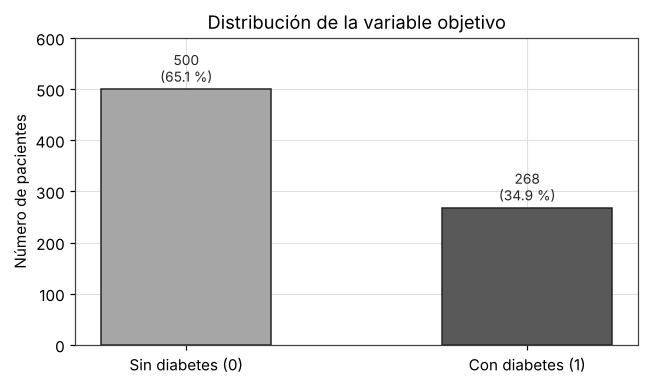

In [16]:
# Figura 1: distribución de la variable objetivo
conteo = df_eda["outcome"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.6))
barras = ax.bar(["Sin diabetes (0)", "Con diabetes (1)"], conteo.values,
                color=[GRIS, GRIS_OSCURO], edgecolor=NEGRO, width=0.5)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8,
            f"{v}\n({v / len(df_eda) * 100:.1f} %)",
            ha="center", va="bottom", fontsize=9, color=NEGRO)
ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Número de pacientes")
ax.set_ylim(0, 600)
plt.tight_layout()
plt.show()

**Figura 1. Distribución de la variable objetivo.**

**Interpretación.** De las 768 pacientes, 500 no tienen diabetes y 268 sí; la clase positiva
pesa el 34.9 %. El desbalance es moderado, pero tiene una consecuencia directa sobre la
evaluación: un clasificador que respondiera siempre "sin diabetes" alcanzaría un 65.1 % de
exactitud sin haber aprendido nada. Ese 65.1 % es el piso contra el que hay que comparar
cualquier resultado de este cuaderno.

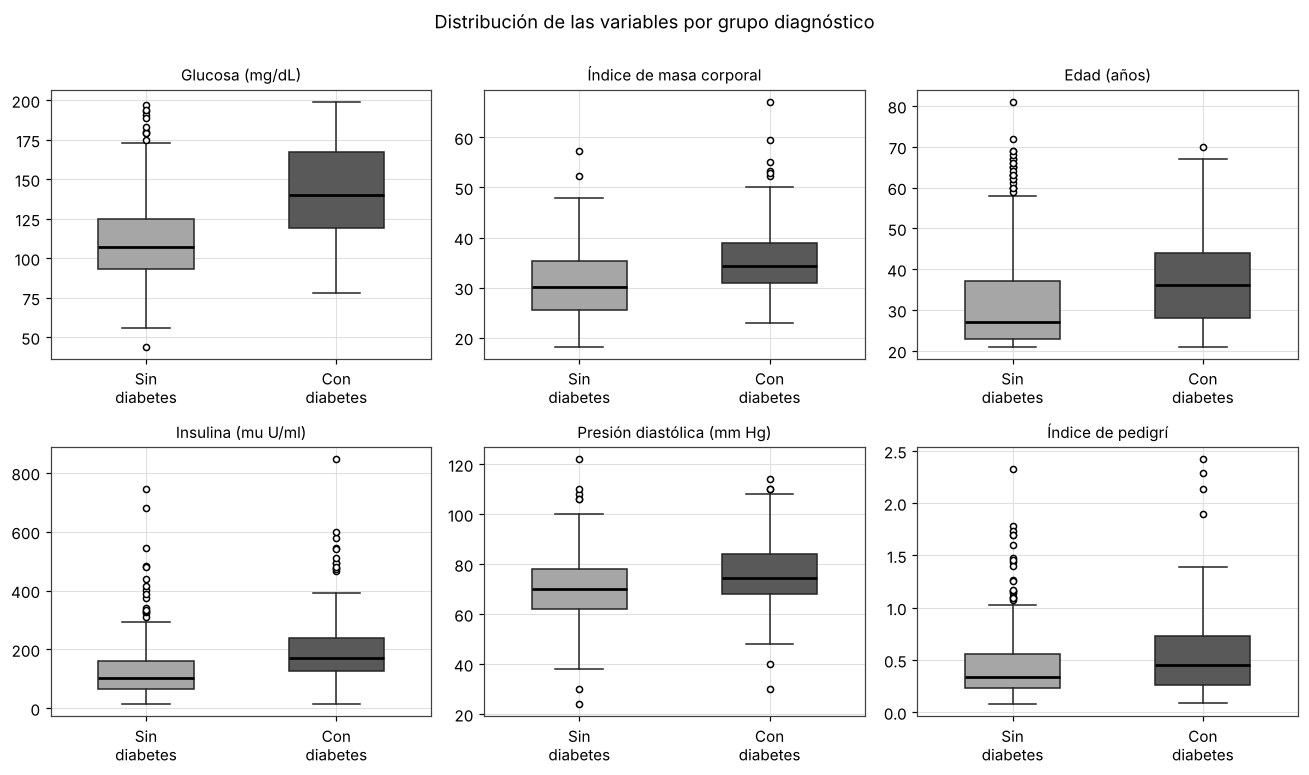

diagnostico,Sin diabetes,Con diabetes,diferencia,dif / desv. estándar
glucose,107.00,140.00,33.00,1.08
age,27.00,36.00,9.00,0.77
bmi,30.10,34.30,4.20,0.61
pregnancies,2.00,4.00,2.00,0.59
insulin,102.50,169.50,67.00,0.56
skin_thickness,27.00,32.00,5.00,0.48
blood_pressure,70.00,74.50,4.50,0.36
diabetes_pedigree,0.34,0.45,0.11,0.34


In [17]:
# Figura 2: comparación de las variables entre los dos grupos diagnósticos
variables_box = ["glucose", "bmi", "age", "insulin", "blood_pressure", "diabetes_pedigree"]
titulos_box = ["Glucosa (mg/dL)", "Índice de masa corporal", "Edad (años)",
               "Insulina (mu U/ml)", "Presión diastólica (mm Hg)", "Índice de pedigrí"]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, var, titulo in zip(axes.ravel(), variables_box, titulos_box):
    datos = [df_eda.loc[df_eda["outcome"] == 0, var].dropna(),
             df_eda.loc[df_eda["outcome"] == 1, var].dropna()]
    bp = ax.boxplot(datos, widths=0.5, patch_artist=True,
                    medianprops=dict(color="black", linewidth=1.8),
                    whiskerprops=dict(color=NEGRO), capprops=dict(color=NEGRO),
                    flierprops=dict(marker="o", markerfacecolor="white",
                                    markeredgecolor="black", markersize=4))
    for parche, color in zip(bp["boxes"], [GRIS, GRIS_OSCURO]):
        parche.set_facecolor(color)
        parche.set_edgecolor(NEGRO)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Sin\ndiabetes", "Con\ndiabetes"])
    ax.set_title(titulo, fontsize=10)

fig.suptitle("Distribución de las variables por grupo diagnóstico", y=1.0)
plt.tight_layout()
plt.show()

# Tabla 4. Medianas por grupo. La diferencia cruda no sirve para comparar variables
# con unidades distintas (67 unidades de insulina no son "más" que 33 de glucosa),
# así que se divide por la desviación estándar de cada variable para poder ordenarlas.
medianas_grupo = df_eda.groupby("diagnostico")[numericas].median().round(2).T
medianas_grupo = medianas_grupo[["Sin diabetes", "Con diabetes"]]
medianas_grupo["diferencia"] = (medianas_grupo["Con diabetes"] -
                                medianas_grupo["Sin diabetes"]).round(2)
# Se calcula sobre las medianas sin redondear, no sobre la columna "diferencia"
# ya redondeada, para que el cociente no arrastre el error del redondeo.
_dif_exacta = (df_eda[df_eda["outcome"] == 1][numericas].median()
               - df_eda[df_eda["outcome"] == 0][numericas].median())
medianas_grupo["dif / desv. estándar"] = (_dif_exacta / df_eda[numericas].std()).round(2)
medianas_grupo = medianas_grupo.sort_values("dif / desv. estándar",
                                            key=abs, ascending=False)
medianas_grupo

**Figura 2. Distribución de las variables por grupo diagnóstico.** · **Tabla 4. Medianas por
grupo diagnóstico.**

**Interpretación.** La glucosa es la variable que más separa a los dos grupos: su mediana pasa
de 107.0 mg/dL en las pacientes sin diabetes a 140.0 en las diagnosticadas y las cajas apenas se
tocan. Aquí hay que tener cuidado con cómo se comparan las variables entre sí. En diferencia
cruda la insulina parece separar más que la glucosa (67 unidades contra 33), pero esa
comparación no significa nada porque las dos variables tienen unidades y dispersiones
distintas. Al dividir la diferencia por la desviación estándar de cada variable el orden queda
claro: glucosa 1.08, edad 0.77, índice de masa corporal 0.61, embarazos 0.59, insulina 0.56,
pliegue cutáneo 0.48, presión diastólica 0.36 e índice de pedigrí 0.34. La insulina baja al
quinto lugar justamente porque su dispersión es enorme.

Ninguna variable separa a los grupos por sí sola, todas las cajas se superponen en algún tramo,
de modo que el problema requiere un modelo multivariado y no un umbral simple.

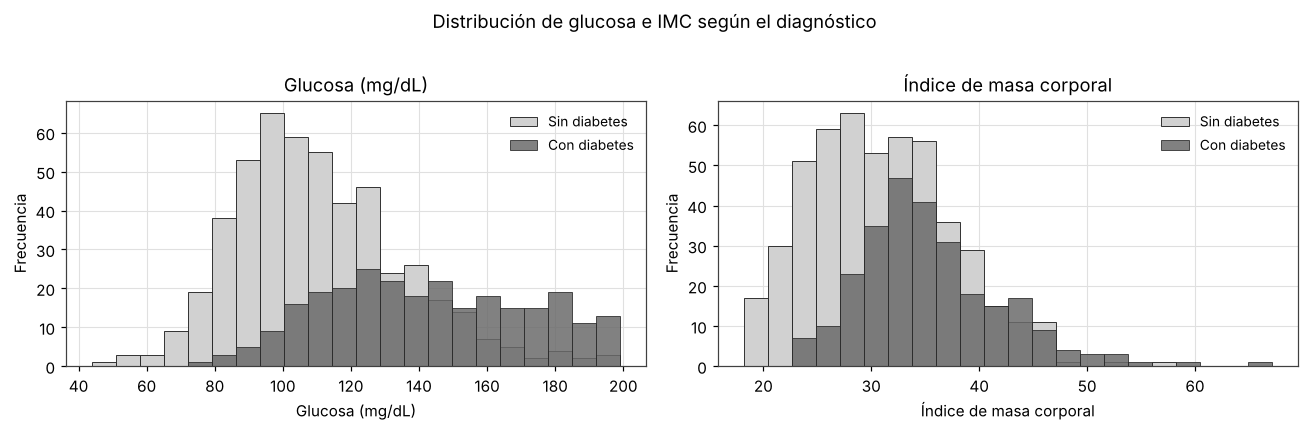

In [18]:
# Figura 3: forma de las distribuciones de glucosa e IMC en cada grupo
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

for ax, var, titulo in zip(axes, ["glucose", "bmi"],
                           ["Glucosa (mg/dL)", "Índice de masa corporal"]):
    bins = np.histogram_bin_edges(df_eda[var].dropna(), bins=22)
    ax.hist(df_eda.loc[df_eda["outcome"] == 0, var].dropna(), bins=bins, color="0.82",
            edgecolor=NEGRO, linewidth=0.6, label="Sin diabetes")
    ax.hist(df_eda.loc[df_eda["outcome"] == 1, var].dropna(), bins=bins, color="0.42",
            edgecolor=NEGRO, linewidth=0.6, alpha=0.85, label="Con diabetes")
    ax.set_title(titulo)
    ax.set_xlabel(titulo)
    ax.set_ylabel("Frecuencia")
    ax.legend(frameon=False, fontsize=9)

fig.suptitle("Distribución de glucosa e IMC según el diagnóstico", y=1.02)
plt.tight_layout()
plt.show()

**Figura 3. Distribución de glucosa e IMC según el diagnóstico.**

**Interpretación.** En glucosa los dos grupos se solapan en la zona media pero las colas son
claramente distintas: de las 101 pacientes por encima de 160 mg/dL, el 82.2 % tiene diagnóstico
positivo, mientras que entre las 209 que no pasan de 100 solo lo tiene el 8.6 %. El IMC muestra el mismo
patrón, aunque mucho más atenuado: el grupo diagnosticado está desplazado a la derecha, pero el
solapamiento es tan grande que el IMC por sí solo no distinguiría a una paciente de otra. Esto
refuerza la lectura de la figura anterior y explica por qué la glucosa aparecerá como la
variable más influyente en los modelos.

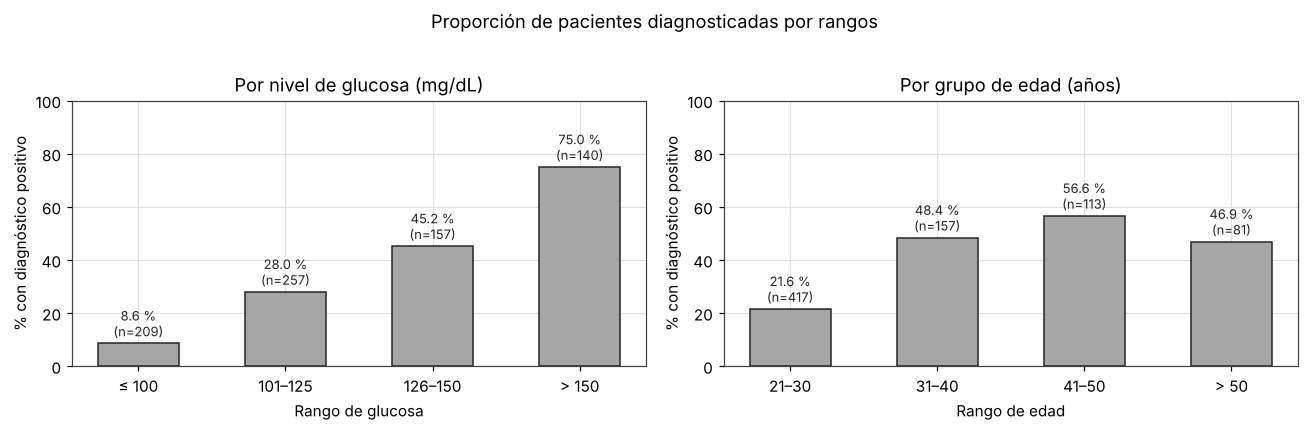

In [19]:
# Figura 4: prevalencia de diabetes por rangos de glucosa y de edad.
# Conecta directamente las dos variables con la pregunta del proyecto.
df_rangos = df_eda.copy()
# pd.cut cierra los intervalos por la derecha, así que el primer tramo incluye
# el valor 100. Las etiquetas lo reflejan para que coincidan con lo que se cuenta.
df_rangos["rango_glucosa"] = pd.cut(
    df_rangos["glucose"], bins=[0, 100, 125, 150, 200],
    labels=["≤ 100", "101–125", "126–150", "> 150"])
df_rangos["rango_edad"] = pd.cut(
    df_rangos["age"], bins=[20, 30, 40, 50, 100],
    labels=["21–30", "31–40", "41–50", "> 50"])  # aquí el cierre por la derecha coincide

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, titulo, etiqueta in [
        (axes[0], "rango_glucosa", "Por nivel de glucosa (mg/dL)", "Rango de glucosa"),
        (axes[1], "rango_edad", "Por grupo de edad (años)", "Rango de edad")]:
    tasa = df_rangos.groupby(col, observed=True)["outcome"].agg(["mean", "count"])
    barras = ax.bar(tasa.index.astype(str), tasa["mean"] * 100,
                    color=GRIS, edgecolor=NEGRO, width=0.55)
    for b, (m, n) in zip(barras, tasa.values):
        ax.text(b.get_x() + b.get_width() / 2, m * 100 + 1.5,
                f"{m * 100:.1f} %\n(n={int(n)})", ha="center", va="bottom",
                fontsize=8.5, color=NEGRO)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("% con diagnóstico positivo")
    ax.set_ylim(0, 100)

fig.suptitle("Proporción de pacientes diagnosticadas por rangos", y=1.02)
plt.tight_layout()
plt.show()

**Figura 4. Proporción de pacientes diagnosticadas por rangos de glucosa y de edad.**

**Interpretación.** El gradiente por glucosa es muy marcado y sigue los umbrales clínicos
habituales: la proporción de diagnósticos positivos pasa del 8.6 % hasta 100 mg/dL al
28.0 % entre 101 y 125, al 45.2 % entre 126 y 150, y al 75.0 % por encima de 150. La edad
muestra un gradiente más suave y además no monótono: sube del 21.6 % en las pacientes de 21 a 30
años al 48.4 % entre 31 y 40 y al 56.6 % entre 41 y 50, pero vuelve a bajar al 46.9 % en las
mayores de 50, lo que puede deberse a que ese último tramo solo reúne 81 pacientes. La cantidad de casos por rango es desigual, así que los porcentajes
de los grupos pequeños son menos confiables y por eso se reporta el `n` sobre cada barra.

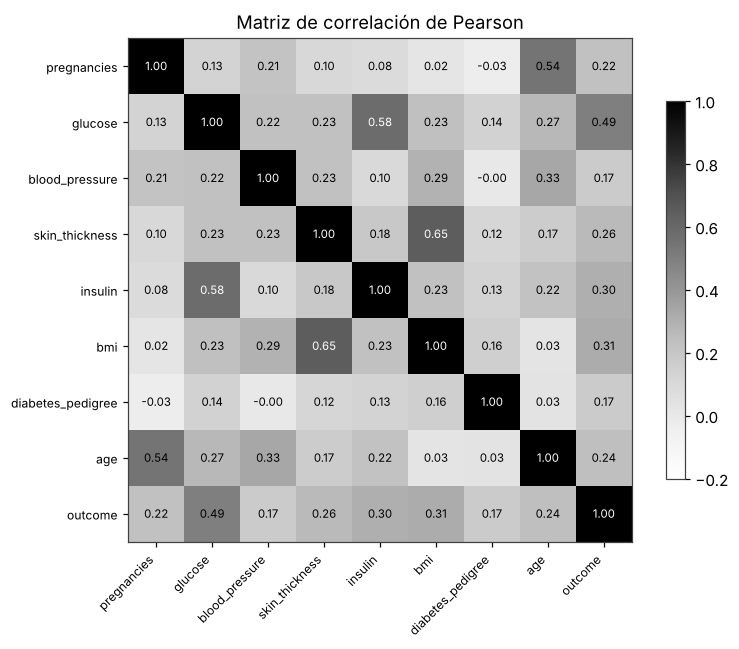

glucose              0.495
bmi                  0.314
insulin              0.303
skin_thickness       0.259
age                  0.238
pregnancies          0.222
diabetes_pedigree    0.174
blood_pressure       0.171
Name: outcome, dtype: float64

In [20]:
# Figura 5: matriz de correlación
corr = df_eda[numericas + ["outcome"]].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="Greys", vmin=-0.2, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        valor = corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if valor > 0.55 else "black")
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

# Correlación con el diagnóstico, ordenada
corr_objetivo = corr["outcome"].drop("outcome").sort_values(ascending=False).round(3)
corr_objetivo

**Figura 5. Matriz de correlación de Pearson.**

**Interpretación.** Calculada ya sin los ceros falsos, la glucosa es la variable más asociada al
diagnóstico (0.495), seguida del índice de masa corporal (0.314), la insulina (0.303), el espesor
del pliegue cutáneo (0.259), la edad (0.238) y el número de embarazos (0.222). Entre las
predictoras aparecen tres relaciones fuertes y esperables: IMC con espesor del pliegue cutáneo
(0.648) —el pliegue del tríceps es precisamente un estimador de grasa corporal—, glucosa con
insulina (0.581) y embarazos con edad (0.544). Esa
redundancia hay que tenerla presente al interpretar los coeficientes de la regresión logística,
porque cuando dos variables miden casi lo mismo el peso se reparte entre ambas y ninguna parece
importante por separado.

Hay que tener presente que estos son coeficientes lineales: una correlación baja no descarta que la
variable aporte al modelo, porque puede tener una relación no lineal con el diagnóstico o ser
útil en combinación con otras. Por eso la selección no se hace recortando por correlación.

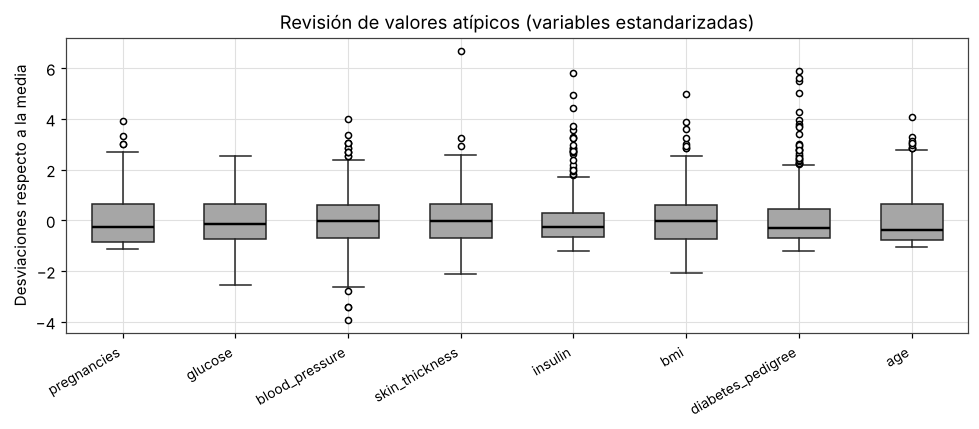

Atípicos por el método IQR (ver tabla de la sección 1.3):
                   atípicos  % atípicos
variable                               
pregnancies               4        0.52
glucose                   0        0.00
blood_pressure           14        1.91
skin_thickness            3        0.55
insulin                  24        6.09
bmi                       8        1.06
diabetes_pedigree        29        3.78
age                       9        1.17


In [21]:
# Figura 6: revisión visual de atípicos en todas las variables numéricas.
# Cada variable se estandariza solo para poder dibujarlas en una misma escala.
estandarizado = (df_eda[numericas] - df_eda[numericas].mean()) / df_eda[numericas].std()

fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot([estandarizado[c].dropna() for c in numericas], widths=0.55,
                patch_artist=True,
                boxprops=dict(facecolor=GRIS, edgecolor=NEGRO),
                medianprops=dict(color="black", linewidth=1.6),
                whiskerprops=dict(color=NEGRO), capprops=dict(color=NEGRO),
                flierprops=dict(marker="o", markerfacecolor="white",
                                markeredgecolor="black", markersize=4))
ax.set_xticks(range(1, len(numericas) + 1))
ax.set_xticklabels(numericas, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Desviaciones respecto a la media")
ax.set_title("Revisión de valores atípicos (variables estandarizadas)")
plt.tight_layout()
plt.show()

print("Atípicos por el método IQR (ver tabla de la sección 1.3):")
print(atipicos_tabla[["atípicos", "% atípicos"]].to_string())

**Figura 6. Revisión de valores atípicos.**

**Interpretación.** En proporción, la insulina es la variable con más valores extremos: 24 casos
fuera del rango intercuartílico, que son el 6.09 % de sus valores medidos. En número absoluto el
índice de pedigrí tiene más casos (29), pero sobre 768 valores completos eso es apenas el 3.78 %.
Después viene la presión diastólica con 14 casos (1.91 %). La glucosa no tiene ninguno. Los extremos de
insulina no parecen errores de registro: de las 24 pacientes por encima del límite, 14 tienen
diagnóstico positivo, es decir el 58.3 %, frente al 31.4 % de las pacientes cuya insulina medida
cae dentro del rango. Eliminarlos habría borrado justamente la señal que buscamos, que es la
razón por la que se conservan.

## 4. Selección y entrenamiento de modelos

### 4.1. Modelos elegidos y por qué

Se entrenan **tres algoritmos**, cada uno en dos versiones —una con la configuración por defecto
y otra con `class_weight='balanced'`— para medir el efecto del desbalance de clases. Seis
modelos en total.

**Regresión logística.** Es el punto de partida natural en un problema binario con predictoras
numéricas: entrega una probabilidad por paciente y coeficientes interpretables, que es justo lo
que se necesita en un contexto clínico donde hay que poder explicar por qué el modelo clasificó
a alguien como caso de riesgo. Requiere escalamiento, que se incluye en su pipeline.

**Árbol de decisión.** Aporta una lógica de reglas legible, del tipo "si la glucosa supera tal
valor y el IMC supera tal otro". Se limita la profundidad a 4 para evitar que memorice el
conjunto de entrenamiento: con 576 registros, un árbol sin restricción llega a hojas con una o
dos pacientes y deja de generalizar.

**Bosque aleatorio.** Se incluye como tercer modelo porque promedia muchos árboles y suele
corregir la inestabilidad del árbol individual. No se le ajustan hiperparámetros más allá de
fijar 300 estimadores, en línea con lo que pide la entrega.

El `class_weight='balanced'` hace que los errores sobre la clase minoritaria pesen más durante el
entrenamiento. Esta es la respuesta directa al desbalance que documentamos y, como se verá, el
factor que más cambia los resultados.

No se realiza búsqueda ni optimización de hiperparámetros, tal como indica la guía de esta
entrega.

In [22]:
# Constructor de pipelines. La imputación va SIEMPRE dentro: así la mediana se
# calcula solo con los datos de entrenamiento de cada ajuste, incluidos los de
# cada partición de la validación cruzada.
def construir_pipeline(modelo, escalar):
    pasos = [("imputacion", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    pasos.append(("clasificador", modelo))
    return Pipeline(pasos)


modelos = {
    "Regresión logística": construir_pipeline(
        LogisticRegression(max_iter=1000, random_state=SEMILLA), escalar=True),
    "Reg. logística balanceada": construir_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced",
                           random_state=SEMILLA), escalar=True),
    "Árbol de decisión": construir_pipeline(
        DecisionTreeClassifier(max_depth=4, random_state=SEMILLA), escalar=False),
    "Árbol balanceado": construir_pipeline(
        DecisionTreeClassifier(max_depth=4, class_weight="balanced",
                               random_state=SEMILLA), escalar=False),
    "Bosque aleatorio": construir_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=SEMILLA), escalar=False),
    "Bosque balanceado": construir_pipeline(
        RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               random_state=SEMILLA), escalar=False),
}

for nombre, pipe in modelos.items():
    print(f"{nombre}: {' → '.join(p[0] for p in pipe.steps)}")

Regresión logística: imputacion → escalado → clasificador
Reg. logística balanceada: imputacion → escalado → clasificador
Árbol de decisión: imputacion → clasificador
Árbol balanceado: imputacion → clasificador
Bosque aleatorio: imputacion → clasificador
Bosque balanceado: imputacion → clasificador


In [23]:
# Antes de fijar la profundidad del árbol en 4, comprobamos qué pasa sin restricción.
# No es un modelo que vayamos a usar: es la evidencia de por qué hace falta limitarlo.
arbol_libre = construir_pipeline(DecisionTreeClassifier(random_state=SEMILLA),
                                 escalar=False).fit(X_train, y_train)
t = arbol_libre.named_steps["clasificador"].tree_
hojas_pequenas = (t.n_node_samples[t.children_left == -1] <= 2).sum()

print("Árbol sin restricción de profundidad:")
print(f"  profundidad alcanzada: {arbol_libre.named_steps['clasificador'].get_depth()}")
print(f"  hojas: {t.n_leaves}, de las cuales {hojas_pequenas} tienen 2 pacientes o menos")
print(f"  F1 en entrenamiento: {f1_score(y_train, arbol_libre.predict(X_train)):.3f}")
print(f"  F1 en prueba:        {f1_score(y_test, arbol_libre.predict(X_test)):.3f}")

Árbol sin restricción de profundidad:
  profundidad alcanzada: 14
  hojas: 108, de las cuales 68 tienen 2 pacientes o menos
  F1 en entrenamiento: 1.000
  F1 en prueba:        0.581


**Interpretación.** Sin restricción el árbol llega a profundidad 14 y genera 108 hojas, 68 de
ellas con dos pacientes o menos, y obtiene un F1 perfecto de 1.000 en entrenamiento frente a
0.581 en prueba. Es decir que memoriza el conjunto de entrenamiento y no generaliza. Eso es lo
que justifica limitar la profundidad a 4 en el modelo que sí usamos.

In [24]:
# Entrenamiento y predicción sobre el conjunto de prueba
predicciones, probabilidades = {}, {}

for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    predicciones[nombre] = pipe.predict(X_test)
    probabilidades[nombre] = pipe.predict_proba(X_test)[:, 1]
    print(f"{nombre}: entrenado y evaluado sobre {len(y_test)} registros de prueba.")

Regresión logística: entrenado y evaluado sobre 192 registros de prueba.
Reg. logística balanceada: entrenado y evaluado sobre 192 registros de prueba.
Árbol de decisión: entrenado y evaluado sobre 192 registros de prueba.
Árbol balanceado: entrenado y evaluado sobre 192 registros de prueba.


Bosque aleatorio: entrenado y evaluado sobre 192 registros de prueba.


Bosque balanceado: entrenado y evaluado sobre 192 registros de prueba.


## 5. Evaluación e interpretación

### 5.1. Métricas comparadas

In [25]:
# Tabla comparativa. Se reportan las métricas globales y, por separado, las de la
# clase positiva, que es la que interesa en un problema de tamizaje.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []

for nombre, pipe in modelos.items():
    p = predicciones[nombre]
    pr = probabilidades[nombre]
    f1_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    filas.append({
        "modelo": nombre,
        "accuracy": round(accuracy_score(y_test, p), 3),
        "precision_1": round(precision_score(y_test, p, zero_division=0), 3),
        "recall_1": round(recall_score(y_test, p), 3),
        "f1_1": round(f1_score(y_test, p), 3),
        "recall_0": round(recall_score(y_test, p, pos_label=0), 3),
        "f1_macro": round(f1_score(y_test, p, average="macro"), 3),
        "AUC": round(roc_auc_score(y_test, pr), 3),
        "F1 val. cruzada": round(f1_cv.mean(), 3),
        "desv. CV": round(f1_cv.std(), 3),
    })

# Tabla 5. Comparación de desempeño. Las columnas con sufijo _1 corresponden a la
# clase positiva; recall_0 es la de la clase negativa y f1_macro el promedio sin pesos.
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion

,accuracy,precision_1,recall_1,f1_1,recall_0,f1_macro,AUC,F1 val. cruzada,desv. CV
modelo,,,,,,,,,
Regresión logística,0.714,0.603,0.522,0.560,0.816,0.674,0.828,0.643,0.027
Reg. logística balanceada,0.729,0.597,0.687,0.639,0.752,0.711,0.829,0.659,0.044
Árbol de decisión,0.750,0.651,0.612,0.631,0.824,0.721,0.767,0.606,0.033
Árbol balanceado,0.677,0.528,0.701,0.603,0.664,0.665,0.698,0.622,0.028
Bosque aleatorio,0.750,0.667,0.567,0.613,0.848,0.714,0.809,0.613,0.029
Bosque balanceado,0.729,0.603,0.657,0.629,0.768,0.708,0.820,0.643,0.034


In [26]:
# Resultados por clase de los seis modelos, incluidos los promedios macro y ponderado.
for nombre in modelos:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, predicciones[nombre],
                                target_names=["Sin diabetes (0)", "Con diabetes (1)"],
                                digits=3, zero_division=0))

===== Regresión logística =====
                  precision    recall  f1-score   support

Sin diabetes (0)      0.761     0.816     0.788       125
Con diabetes (1)      0.603     0.522     0.560        67

        accuracy                          0.714       192
       macro avg      0.682     0.669     0.674       192
    weighted avg      0.706     0.714     0.708       192

===== Reg. logística balanceada =====
                  precision    recall  f1-score   support

Sin diabetes (0)      0.817     0.752     0.783       125
Con diabetes (1)      0.597     0.687     0.639        67

        accuracy                          0.729       192
       macro avg      0.707     0.719     0.711       192
    weighted avg      0.741     0.729     0.733       192

===== Árbol de decisión =====
                  precision    recall  f1-score   support

Sin diabetes (0)      0.798     0.824     0.811       125
Con diabetes (1)      0.651     0.612     0.631        67

        accuracy      

In [27]:
# Tabla 6. Sobreajuste medido como corresponde: la MISMA métrica sobre entrenamiento
# y sobre prueba. Comparar la exactitud en prueba contra el F1 de validación cruzada
# no mide sobreajuste, porque son métricas distintas sobre conjuntos distintos.
filas = []
for nombre, pipe in modelos.items():
    f1_tr = f1_score(y_train, pipe.predict(X_train))
    f1_te = f1_score(y_test, predicciones[nombre])
    filas.append({"modelo": nombre,
                  "F1 entrenamiento": round(f1_tr, 3),
                  "F1 prueba": round(f1_te, 3),
                  "brecha": round(f1_tr - f1_te, 3)})

generalizacion = pd.DataFrame(filas).set_index("modelo").sort_values("brecha")
generalizacion

,F1 entrenamiento,F1 prueba,brecha
modelo,,,
Reg. logística balanceada,0.690,0.639,0.051
Regresión logística,0.670,0.560,0.110
Árbol de decisión,0.752,0.631,0.122
Árbol balanceado,0.750,0.603,0.147
Bosque balanceado,1.000,0.629,0.371
Bosque aleatorio,1.000,0.613,0.387


**Tabla 6. Brecha de generalización.**

**Interpretación.** Este es el contraste que sí permite hablar de sobreajuste, y cambia una
conclusión que parecía evidente. Los dos bosques aleatorios alcanzan un F1 perfecto de 1.000
sobre los datos de entrenamiento y caen a 0.613 y 0.629 en prueba: brechas de 0.387 y 0.371, con
diferencia las mayores del grupo. Son ellos, y no el árbol individual, los que memorizan el
conjunto de entrenamiento. Los dos árboles de profundidad 4 quedan en 0.122 y 0.147, y la
regresión logística balanceada es la que mejor generaliza con una brecha de apenas 0.051.

Que el bosque aleatorio sobreajuste no significa que sea inservible: sigue teniendo un AUC de
0.809 y un desempeño en prueba comparable al del árbol. Pero sí explica por qué su ventaja
aparente no se sostiene, y añade un argumento a favor del modelo lineal en un conjunto de este
tamaño.

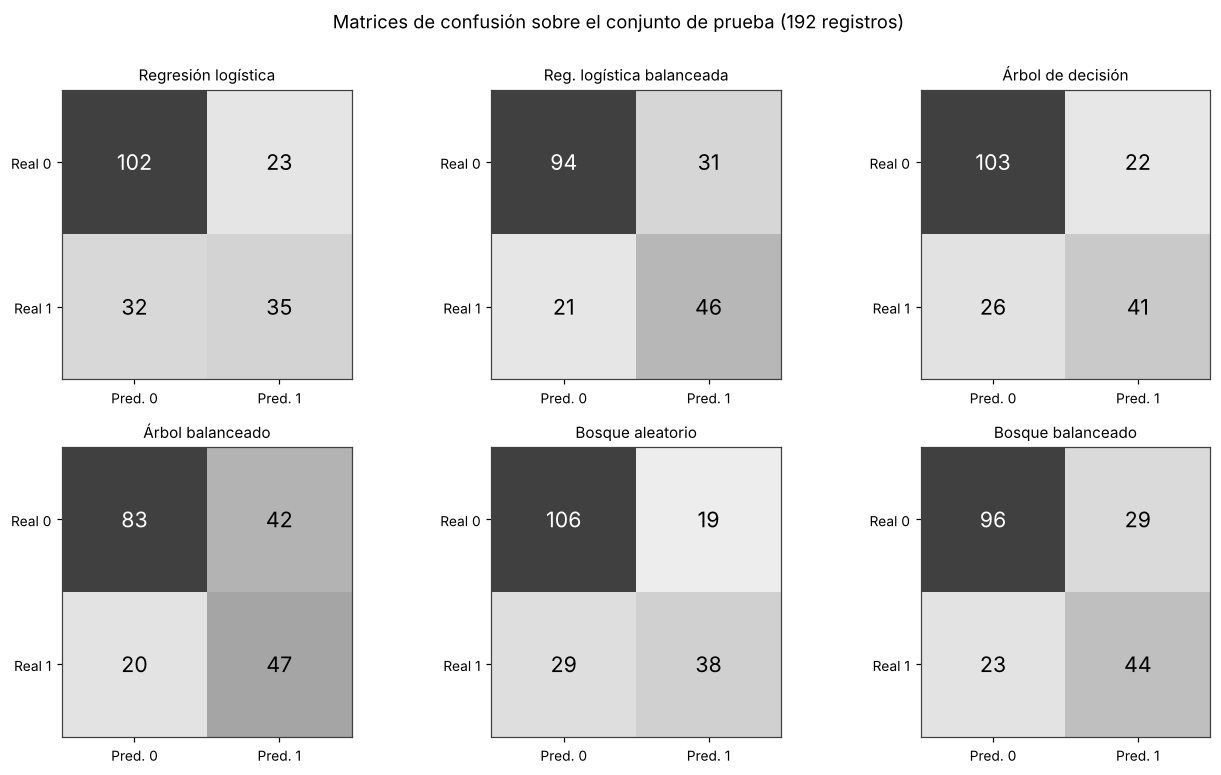

,verdaderos_neg,falsos_pos,falsos_neg,verdaderos_pos
modelo,,,,
Regresión logística,102,23,32,35
Reg. logística balanceada,94,31,21,46
Árbol de decisión,103,22,26,41
Árbol balanceado,83,42,20,47
Bosque aleatorio,106,19,29,38
Bosque balanceado,96,29,23,44


In [28]:
# Figura 7: matrices de confusión de los seis modelos
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (nombre, p) in zip(axes.ravel(), predicciones.items()):
    cm = confusion_matrix(y_test, p)
    ax.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.25)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() * 0.7 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred. 0", "Pred. 1"], fontsize=9)
    ax.set_yticklabels(["Real 0", "Real 1"], fontsize=9)
    ax.set_title(nombre, fontsize=10)
    ax.grid(False)

fig.suptitle("Matrices de confusión sobre el conjunto de prueba (192 registros)",
             y=1.0)
plt.tight_layout()
plt.show()

# Tabla 7. Desglose explícito de aciertos y errores de cada modelo.
errores = []
for nombre, p in predicciones.items():
    vn, fp, fn, vp = confusion_matrix(y_test, p).ravel()
    errores.append({"modelo": nombre, "verdaderos_neg": vn, "falsos_pos": fp,
                    "falsos_neg": fn, "verdaderos_pos": vp})
pd.DataFrame(errores).set_index("modelo")

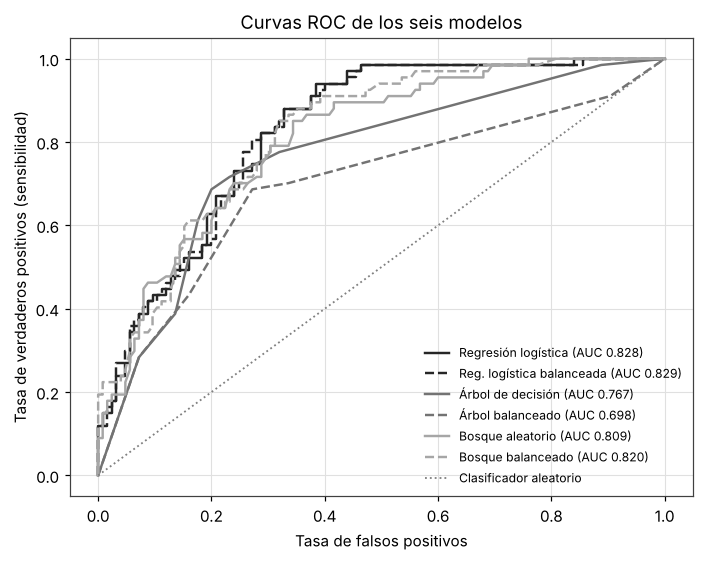

In [29]:
# Figura 8: curvas ROC
fig, ax = plt.subplots(figsize=(6.5, 5.2))
estilos = ["-", "--", "-", "--", "-", "--"]
colores = ["0.15", "0.15", "0.45", "0.45", "0.65", "0.65"]

for (nombre, pr), estilo, color in zip(probabilidades.items(), estilos, colores):
    fpr, tpr, _ = roc_curve(y_test, pr)
    ax.plot(fpr, tpr, estilo, color=color, linewidth=1.6,
            label=f"{nombre} (AUC {roc_auc_score(y_test, pr):.3f})")

ax.plot([0, 1], [0, 1], ":", color="0.5", linewidth=1.2, label="Clasificador aleatorio")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.set_title("Curvas ROC de los seis modelos")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Figura 7. Matrices de confusión de los seis modelos sobre el conjunto de prueba.**
La diagonal principal son los aciertos. La celda inferior izquierda de cada matriz son los
falsos negativos: pacientes con diabetes clasificadas como sanas, que es el error que más pesa
en este problema.

**Figura 8. Curvas ROC de los seis modelos.** Cuanto más arriba y a la izquierda pasa la curva,
mejor separa el modelo las dos clases en todo el rango de umbrales posibles. La diagonal
punteada corresponde a un clasificador que decidiera al azar.

### 5.2. Qué tipo de error importa en este problema

Antes de elegir un modelo hay que decidir qué error pesa más, porque las dos equivocaciones no
cuestan lo mismo.

Un **falso negativo** es una paciente con diabetes a la que el modelo clasifica como sana. En un
tamizaje eso significa que se va sin confirmación diagnóstica y sin tratamiento, y la enfermedad
sigue avanzando hacia las complicaciones que describimos en la introducción del proyecto.

Un **falso positivo** es una paciente sana marcada como caso de riesgo. El costo es una consulta
de confirmación que resultará negativa: tiempo médico y una preocupación innecesaria, pero
ningún daño clínico.

Dada esa asimetría, la métrica principal en este problema es la **exhaustividad de la clase
positiva** (el recall de la clase 1), pero no puede usarse sola: un modelo que marcara a todas
las pacientes como positivas tendría una exhaustividad perfecta y sería inútil. Por eso se lee
junto al **F1 de esa misma clase**, que la combina con la precisión y penaliza ese atajo. La
exactitud global queda en segundo plano porque, con un 65.1 % de pacientes sanas, un modelo puede
elevarla simplemente acertando en la clase mayoritaria, que es la que menos importa detectar.

In [30]:
# Tabla 8. Cómo se reordenan los modelos según el criterio que se use.
orden = pd.DataFrame({
    "puesto por accuracy": comparacion["accuracy"].rank(ascending=False).astype(int),
    "accuracy": comparacion["accuracy"],
    "puesto por recall_1": comparacion["recall_1"].rank(ascending=False).astype(int),
    "recall_1": comparacion["recall_1"],
    "f1_1": comparacion["f1_1"],
    "AUC": comparacion["AUC"],
}).sort_values("puesto por recall_1")
orden

,puesto por accuracy,accuracy,puesto por recall_1,recall_1,f1_1,AUC
modelo,,,,,,
Árbol balanceado,6,0.677,1,0.701,0.603,0.698
Reg. logística balanceada,3,0.729,2,0.687,0.639,0.829
Bosque balanceado,3,0.729,3,0.657,0.629,0.820
Árbol de decisión,1,0.750,4,0.612,0.631,0.767
Bosque aleatorio,1,0.750,5,0.567,0.613,0.809
Regresión logística,5,0.714,6,0.522,0.560,0.828


**Tabla 8. Ordenamiento de los modelos por exactitud frente a exhaustividad.**

**Interpretación.** Los dos ordenamientos están casi invertidos. El árbol de decisión y el bosque
aleatorio, primeros en exactitud con 0.750, caen al cuarto y quinto puesto en exhaustividad de la
clase positiva. El árbol balanceado, último en exactitud con 0.677, es el primero en
exhaustividad con 0.701. Esa inversión es el motivo por el que la elección del modelo no puede
apoyarse en la exactitud, y también la razón por la que no basta con mirar la exhaustividad
sola: el árbol balanceado la consigue a costa de bajar su precisión a 0.528 y su AUC a 0.698.

### 5.3. Comparación e interpretación de los resultados

**El modelo con mejor exactitud no es el mejor para este problema.** El árbol de decisión y el
bosque aleatorio empatan en la exactitud más alta, 0.750, pero detectan 41 y 38 de las 67
pacientes diabéticas del conjunto de prueba. La regresión logística balanceada tiene una
exactitud menor, 0.729, y detecta 46. La explicación está en la Tabla 8: esos dos modelos
aciertan más veces en total porque aciertan mucho en la clase mayoritaria, que es la que no
interesa detectar.

**La regresión logística balanceada es la mejor opción, aunque no gana en todo.** Hay que ser
precisos con lo que encabeza y lo que no. Tiene el mayor F1 de la clase positiva (0.639), la
menor brecha de generalización (0.051) y el mayor F1 bajo validación cruzada (0.659). En cambio
**no** tiene la mayor exhaustividad: el árbol balanceado la supera con 0.701 frente a 0.687. Lo
que descalifica al árbol balanceado es el precio que paga por esa sensibilidad, con la precisión
desplomada a 0.528, el F1 en 0.603 y el AUC en 0.698, el más bajo de los seis. Dicho de otra
forma, la regresión logística balanceada no es la que más pacientes detecta, sino la que mejor
combina detección y precisión.

Hay dos ventajas suyas que conviene no exagerar. Su AUC de 0.829 supera al de la regresión sin
balancear por 0.001, diferencia que en un conjunto de prueba de 192 registros no significa nada.
Y su F1 en validación cruzada, 0.659 con una desviación de 0.044, se solapa con el 0.643 del
bosque balanceado: la validación cruzada confirma que el modelo es competitivo, pero no alcanza
para declararlo superior por sí sola. Tampoco debe contarse el F1 como evidencia independiente
de la exhaustividad, porque el primero se calcula a partir de la segunda.

**La ponderación de clases es el factor que más mueve los resultados.** En la regresión logística,
activar `class_weight='balanced'` sube la exhaustividad de 0.522 a 0.687, de 35 a 46 pacientes
detectadas de 67, a cambio de que los falsos positivos pasen de 23 a 31. Para un tamizaje el
intercambio es favorable: once diagnósticos adicionales a cambio de ocho consultas de
confirmación. En el bosque aleatorio el efecto apunta en la misma dirección de forma más
moderada. En el árbol produce el desplome de precisión ya descrito.

**Los bosques aleatorios son los que sobreajustan, no el árbol.** Esta fue la conclusión que más
nos sorprendió, y solo apareció al medir el sobreajuste como corresponde. Mirando únicamente la
Tabla 5 parecería que el árbol individual es el modelo problemático, porque tiene el F1 más bajo
en validación cruzada (0.606) entre los no balanceados. Pero la Tabla 6 muestra que los dos
bosques obtienen un F1 de 1.000 sobre los datos de entrenamiento y caen por encima de 0.37 al
pasar a prueba, mientras que los árboles de profundidad 4 se quedan en 0.122 y 0.147. La
restricción de profundidad cumplió su función; los 300 árboles del bosque, sin esa restricción,
memorizan el conjunto.

**El bosque aleatorio no superó a la regresión logística.** Con 576 registros de entrenamiento y
diez variables numéricas sin interacciones complejas, el modelo lineal rinde igual o mejor que el
ensamble. La complejidad adicional no se tradujo en mejor desempeño y sí en menor
interpretabilidad y en una brecha de generalización siete veces mayor.

**Qué errores quedan.** El mejor modelo deja pasar 21 de las 67 pacientes diabéticas del conjunto
de prueba, un desempeño insuficiente para cualquier uso clínico. Los falsos negativos se
concentran en la zona intermedia de las distribuciones, donde los dos grupos se solapan y donde
ninguna de las variables disponibles alcanza para discriminar.

In [31]:
# ¿Dónde se equivoca el mejor modelo? Perfil de los falsos negativos.
mejor = "Reg. logística balanceada"
resultado = X_test.copy()
resultado["real"] = y_test
resultado["predicho"] = predicciones[mejor]

fn = resultado[(resultado["real"] == 1) & (resultado["predicho"] == 0)]
vp = resultado[(resultado["real"] == 1) & (resultado["predicho"] == 1)]

# Tabla 9. Perfil de los falsos negativos del modelo elegido.
print(f"Modelo: {mejor}")
print(f"Falsos negativos: {len(fn)} de {int(y_test.sum())} pacientes diabéticas")
print()
comparar = pd.DataFrame({
    "falsos negativos (mediana)": fn[["glucose", "bmi", "age", "insulin"]].median(),
    "detectadas correctamente (mediana)": vp[["glucose", "bmi", "age", "insulin"]].median(),
}).round(2)
comparar["diferencia"] = (comparar.iloc[:, 1] - comparar.iloc[:, 0]).round(2)
comparar

Modelo: Reg. logística balanceada
Falsos negativos: 21 de 67 pacientes diabéticas



,falsos negativos (mediana),detectadas correctamente (mediana),diferencia
glucose,123.0,149.5,26.5
bmi,32.0,35.8,3.8
age,29.0,38.0,9.0
insulin,115.0,215.0,100.0


In [32]:
# Variables más influyentes según los dos enfoques, para cerrar la primera mitad
# de la pregunta de investigación.
log_reg = modelos[mejor].named_steps["clasificador"]
coeficientes = pd.Series(log_reg.coef_[0], index=X.columns).sort_values(key=abs,
                                                                       ascending=False)

bosque = modelos["Bosque balanceado"].named_steps["clasificador"]
importancias = pd.Series(bosque.feature_importances_, index=X.columns).sort_values(
    ascending=False)

# Tabla 10. Variables más influyentes. Ambas columnas provienen de los modelos
# balanceados, que son los que se comparan en el análisis.
influencia = pd.DataFrame({
    "coef. reg. logística balanceada": coeficientes.round(3),
    "importancia bosque balanceado": importancias.round(3),
})
influencia

,coef. reg. logística balanceada,importancia bosque balanceado
age,0.131,0.127
blood_pressure,-0.051,0.076
bmi,0.767,0.162
diabetes_pedigree,0.295,0.112
glucose,1.180,0.266
insulin,0.031,0.096
insulin_faltante,0.224,0.010
pregnancies,0.423,0.075
skin_thickness,-0.081,0.067
skin_thickness_faltante,-0.043,0.010


**Interpretación.** Los dos enfoques coinciden en las dos primeras posiciones: la glucosa es con
diferencia la variable más influyente (coeficiente 1.180 en la regresión, importancia 0.266 en el
bosque) y el índice de masa corporal queda segunda en ambos (0.767 y 0.162). A partir de ahí
difieren: la regresión da el tercer lugar al número de embarazos (0.423) y el bosque a la edad
(0.127), lo cual tiene sentido porque esas dos variables están correlacionadas entre sí (0.544) y
cada modelo reparte el peso de forma distinta. El índice de pedigrí familiar ocupa el cuarto
lugar en los dos casos.

Un detalle que conviene mirar de cerca: la insulina tiene una correlación apreciable con el
diagnóstico (0.303) y sin embargo su coeficiente en la regresión es casi nulo (0.031). La
explicación está en la redundancia que ya mostraba la matriz de correlación: la insulina está
fuertemente asociada a la glucosa (0.581), así que una vez que el modelo tiene la glucosa, la
insulina aporta poco nuevo. Algo parecido ocurre entre el IMC y el espesor del pliegue cutáneo,
que se reparten el peso por medir cosas parecidas.

Los coeficientes de la regresión están sobre variables estandarizadas, así que son comparables
entre sí, pero hay que leerlos con dos cuidados. Primero, no miden cambios en la probabilidad
sino en el logaritmo de las probabilidades relativas (log-odds): el efecto sobre la probabilidad
final no es constante y depende del valor de las demás variables. Segundo, no son efectos
causales, solo asociaciones dentro de este conjunto de datos y de esta población.

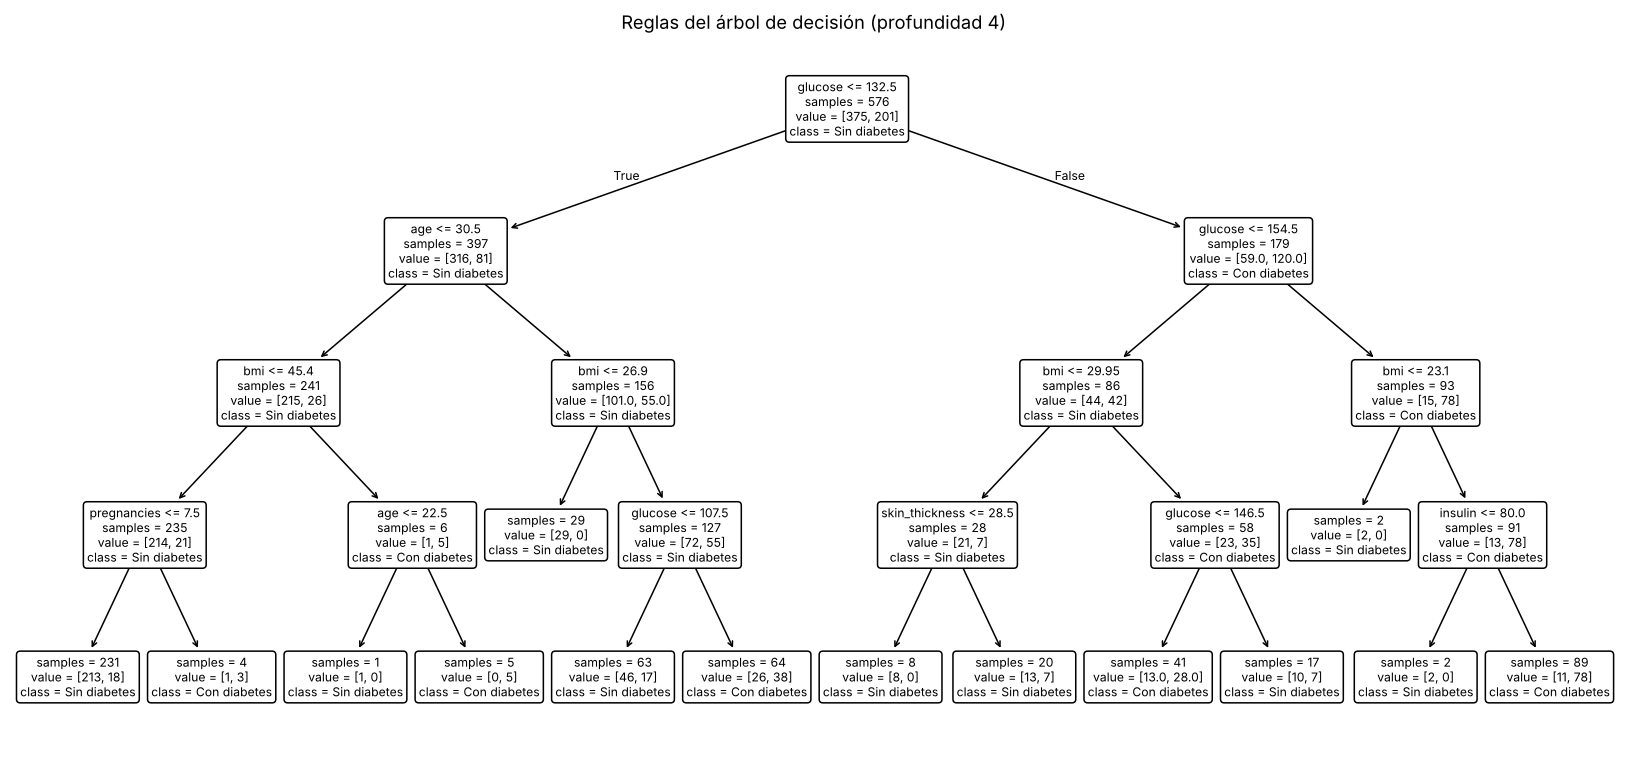

In [33]:
# Figura 9: reglas del árbol de decisión, como lectura complementaria.
# Un árbol de profundidad 4 se puede leer directamente, y eso tiene valor clínico
# aunque no sea el modelo elegido.
fig, ax = plt.subplots(figsize=(15, 7))
plot_tree(modelos["Árbol de decisión"].named_steps["clasificador"],
          feature_names=X.columns, class_names=["Sin diabetes", "Con diabetes"],
          filled=False, rounded=True, fontsize=8, ax=ax, impurity=False)
ax.set_title("Reglas del árbol de decisión (profundidad 4)")
plt.tight_layout()
plt.show()

**Figura 9. Reglas del árbol de decisión (profundidad 4).**

**Interpretación.** La primera partición del árbol separa por glucosa en 132.5 mg/dL, lo que
coincide con todo lo observado antes y con los umbrales clínicos de referencia. A partir de ahí
combina edad, IMC y, en las ramas más profundas, embarazos, pliegue cutáneo e insulina. La
lectura es directa: la rama de glucosa superior a 154.5, índice de masa corporal por encima de
23.1 e insulina por encima de 80 termina en una hoja con 89 pacientes, de las cuales 78 tienen
diagnóstico positivo. Llama la atención que el
índice de pedigrí familiar no aparece en ninguna partición de este árbol, a pesar de ocupar el
cuarto lugar entre las variables influyentes de los otros dos modelos; es un recordatorio de que
cada algoritmo construye su propia jerarquía. Esa transparencia es la principal virtud del árbol
frente al bosque aleatorio, aunque su desempeño sea menos estable.

## 6. Registro de uso de inteligencia artificial

El detalle completo, con los prompts íntegros, los problemas detectados y los ajustes
realizados, está en la sección correspondiente del informe en PDF que acompaña a esta entrega.
En resumen: se utilizó Claude (Anthropic) como apoyo para organizar el cuaderno, redactar
comentarios y revisar código. Todas las cifras que aparecen en el texto se recalcularon
ejecutando el cuaderno, no se tomaron de la herramienta. Las decisiones metodológicas —mover la
imputación al pipeline, conservar los atípicos, usar la exhaustividad de la clase positiva como
criterio de selección y mantener la variable `insulin` con marcador de ausencia— fueron del
grupo, y dos de ellas contradicen sugerencias iniciales de la herramienta.

## 7. Conclusiones del notebook

**Principales hallazgos del análisis exploratorio.** La glucosa es la variable que mejor
diferencia a los dos grupos, medida como diferencia de medianas dividida por la desviación
estándar: 1.08 frente al 0.77 de la edad, el 0.61 del índice de masa corporal y el 0.56 de la
insulina. Su mediana pasa de 107.0 a 140.0 mg/dL entre pacientes sin y con diagnóstico, y la
proporción de casos positivos crece del 8.6 % en quienes no pasan de 100 mg/dL al 75.0 % en
quienes superan 150. La presión diastólica y el índice de pedigrí aportan poco por sí solos.
Ninguna variable separa a los grupos de manera limpia, lo que confirma que el problema requiere
un modelo multivariado. El análisis dejó a la vista además dos condicionantes de todo lo demás:
un desbalance de 65.1 % contra 34.9 % y una redundancia fuerte entre el índice de masa corporal y
el espesor del pliegue cutáneo (0.648).

**Qué solución produjo los resultados más adecuados.** La regresión logística con
`class_weight='balanced'`. Detecta 46 de las 67 pacientes diabéticas del conjunto de prueba, con
una exhaustividad de 0.687 y un F1 de 0.639 sobre la clase positiva.

**Qué evidencia respalda esa elección.** Tres resultados: el mayor F1 de la clase positiva
(0.639), la menor brecha entre entrenamiento y prueba (0.051 frente a 0.122 del árbol y 0.371 del
bosque balanceado) y el mayor F1 bajo validación cruzada (0.659). Hay que precisar que **no** es
el primero en exhaustividad: el árbol balanceado la supera con 0.701, pero a costa de bajar su
precisión a 0.528 y su AUC a 0.698. Tampoco es el primero en exactitud, donde lo superan el árbol
y el bosque con 0.750, y esa es la razón por la que no elegimos con ese criterio: en un tamizaje
un falso negativo deja a una paciente sin tratamiento mientras que un falso positivo solo cuesta
una consulta de confirmación. También hay que ser honestos con el alcance de la validación
cruzada: con una desviación de 0.044, la diferencia entre 0.659 y el 0.643 del bosque balanceado
no es concluyente por sí sola.

**Errores y limitaciones identificados.** El modelo elegido deja pasar 21 pacientes diabéticas de
67, un desempeño insuficiente para cualquier uso clínico real; los casos que se le escapan se
concentran en la zona de glucosa intermedia, donde los dos grupos se solapan. A eso se suman
cuatro limitaciones. El conjunto tiene 768 registros, pocos para un problema de salud, y con 192
en prueba el movimiento de dos o tres pacientes desplaza las métricas en varios puntos.
Corresponden exclusivamente a mujeres mayores de 21 años de una sola comunidad indígena, de modo
que los resultados no generalizan a otras poblaciones. Casi la mitad de los valores de insulina y
cerca de un tercio de los del pliegue cutáneo están ausentes, así que lo que el modelo aprende de
esas dos variables descansa en buena parte sobre valores imputados. Y queda una fuga residual que
conviene declarar: aunque el modelado respeta la separación entre entrenamiento y prueba, el
análisis exploratorio y la decisión de conservar los atípicos se tomaron mirando el conjunto
completo, etiquetas incluidas. No afecta a las métricas reportadas, pero sí significa que esas
decisiones no fueron del todo ciegas al conjunto de prueba.

Por último, todo lo reportado aquí son asociaciones dentro de este conjunto, no relaciones
causales.

**Lo que queda para el tercer corte.** Ajuste de hiperparámetros, que en esta entrega no se
realizó; evaluación de métodos de imputación más sofisticados frente a la mediana, sobre todo
para la insulina; exploración del umbral de decisión, que por defecto está en 0.5 y podría
moverse para privilegiar aún más la sensibilidad; y la redacción del artículo final con estos
resultados consolidados.

In [34]:
# Se guarda la versión final de los datos para el tercer corte.
# Nota: se guardan los NaN tal cual, sin imputar, porque la imputación pertenece
# al pipeline y no al conjunto de datos.
final = X.copy()
final["outcome"] = y
final.to_csv("diabetes_avance2.csv", index=False)

print("Archivo 'diabetes_avance2.csv' guardado.")
print(f"Dimensiones: {final.shape[0]} filas × {final.shape[1]} columnas")
print(f"Valores faltantes conservados como NaN: {int(final.isnull().sum().sum())}")

Archivo 'diabetes_avance2.csv' guardado.
Dimensiones: 768 filas × 11 columnas
Valores faltantes conservados como NaN: 652


---

# Tercer corte — Actividad 1

## 8. Revisión del rendimiento del modelo del segundo corte

El tercer corte parte de lo ya construido: el mismo conjunto de datos, el mismo pipeline y las
mismas métricas. Lo que cambia es el objetivo. Aquí no se repite el análisis exploratorio; se
revisa el rendimiento del modelo, se corrige lo que haga falta y el resultado se integra en una
aplicación web desplegada en Streamlit Community Cloud.

El orden de trabajo de esta parte del cuaderno es el siguiente:

| Sección | Qué se hace |
|---|---|
| 8 | Se comprueban las métricas del segundo corte y se revisa el pipeline con la lista de verificación de calidad |
| 9 | Se optimiza el modelo: estrategia de imputación, hiperparámetros y umbral de decisión |
| 10 | Se serializa el pipeline completo con `joblib` |
| 11 | Se registran los casos de prueba con los que se verifica que la aplicación devuelve lo mismo que el cuaderno |
| 12 | Se exportan los archivos que van al repositorio |
| 13 | Conclusiones del corte |

### 8.1. Comprobación de las métricas reportadas

Antes de tocar nada hay que confirmar que las cifras del segundo informe se reproducen. La celda
siguiente compara, una por una, las métricas de la Tabla 5 del informe contra lo que acaba de
calcular este cuaderno. Si alguna no coincidiera, la ejecución se detendría.

In [35]:
# Verificación de reproducibilidad: las cifras declaradas en la Tabla 5 del segundo informe
# frente a lo que este cuaderno acaba de calcular. Cualquier diferencia detiene la ejecución.
tabla5_informe = {
    #  modelo                     exactitud, precisión_1, exhaustividad_1, F1_1, AUC
    "Regresión logística":        (0.714, 0.603, 0.522, 0.560, 0.828),
    "Reg. logística balanceada":  (0.729, 0.597, 0.687, 0.639, 0.829),
    "Árbol de decisión":          (0.750, 0.651, 0.612, 0.631, 0.767),
    "Árbol balanceado":           (0.677, 0.528, 0.701, 0.603, 0.698),
    "Bosque aleatorio":           (0.750, 0.667, 0.567, 0.613, 0.809),
    "Bosque balanceado":          (0.729, 0.603, 0.657, 0.629, 0.820),
}

discrepancias = []
for nombre, (acc, pre, exh, f1v, auc) in tabla5_informe.items():
    fila = comparacion.loc[nombre]
    for etiqueta, esperado, obtenido in [
        ("exactitud", acc, fila["accuracy"]), ("precisión", pre, fila["precision_1"]),
        ("exhaustividad", exh, fila["recall_1"]), ("F1", f1v, fila["f1_1"]),
        ("AUC", auc, fila["AUC"])]:
        if abs(esperado - obtenido) > 0.0005:
            discrepancias.append(f"{nombre} — {etiqueta}: informe {esperado}, cuaderno {obtenido}")

assert not discrepancias, "No se reprodujeron las métricas:\n" + "\n".join(discrepancias)
print("Las 30 métricas de la Tabla 5 del segundo informe se reproducen sin diferencias.")
print(f"Conjunto de prueba: {len(y_test)} registros, {int(y_test.sum())} positivos.")

Las 30 métricas de la Tabla 5 del segundo informe se reproducen sin diferencias.
Conjunto de prueba: 192 registros, 67 positivos.


### 8.2. La alerta del 70 % se activa

La guía de la actividad establece que si la exactitud o la métrica principal queda por debajo de
0.70 hay que revisar el pipeline antes de integrarlo en la aplicación. Conviene mirar las dos
cifras del modelo que elegimos en el segundo corte:

- **Exactitud: 0.729.** Por encima del umbral.
- **Exhaustividad de la clase positiva: 0.687.** Por debajo.

Y la métrica principal de este proyecto es la segunda, no la primera. Quedó declarada así en la
sección 5.7 del informe y por una razón que no ha cambiado: en un tamizaje un falso negativo
deja a una paciente sin tratamiento, mientras que un falso positivo solo cuesta una consulta de
confirmación. De modo que la alerta se activa y la revisión del pipeline no es opcional.

Es además la misma deuda que el segundo informe dejó anotada como pendiente para este corte: el
ajuste de hiperparámetros, la exploración del umbral de decisión y la evaluación de métodos de
imputación distintos de la mediana.

### 8.3. Lista de verificación de calidad del modelado

La guía remite a la ficha técnica de revisión de calidad. Estos son sus ocho puntos aplicados a
nuestro pipeline, con el estado en que lo deja el segundo corte:

| Punto a verificar | Estado al cerrar el segundo corte |
|---|---|
| Tratamiento de los datos | **Resuelto.** Los ceros imposibles de cinco variables clínicas quedaron como nulos explícitos y se añadieron dos marcadores de ausencia. |
| Separación entre entrenamiento y prueba | **Resuelto.** División estratificada 576 / 192 con semilla 42; ningún modelo vio datos de prueba. |
| Validación cruzada | **Resuelto.** Estratificada de cinco particiones sobre el conjunto de entrenamiento, con desviación reportada. |
| Fuga de información | **Resuelto en lo esencial.** La imputación y el escalamiento viven dentro del pipeline. Queda declarada la fuga residual del análisis exploratorio, que se hizo sobre los 768 registros. |
| Desbalance | **Tratado parcialmente.** Se usó `class_weight='balanced'`, que reparte el peso según la frecuencia de cada clase. Nunca se probó una ponderación distinta. |
| Colinealidad | **Documentada.** Tres pares con correlación alta: IMC con pliegue cutáneo (0.648), glucosa con insulina (0.581), embarazos con edad (0.544). No se aplicó ninguna regularización que la contuviera. |
| Sobreajuste | **Medido.** La brecha de generalización del modelo elegido es 0.051, la menor de las seis configuraciones. Los dos bosques, en cambio, memorizan el entrenamiento. |
| Hiperparámetros | **Sin tratar.** Todos los modelos corrieron con la configuración por defecto, por indicación de la guía del segundo corte. |

Los tres puntos que quedan abiertos —desbalance, colinealidad e hiperparámetros— apuntan al mismo
lugar y son los que ataca la sección siguiente. La ponderación de clases y la fuerza de la
regularización son hiperparámetros; la regularización es además el mecanismo estándar para
contener la colinealidad. Es decir que el ajuste pendiente no es un trámite, sino justo la
herramienta que faltaba.

## 9. Optimización del modelo

### 9.1. Criterio de optimización

Para optimizar hay que fijar primero qué se maximiza, y la exactitud no sirve: la Tabla 8 del
segundo corte mostró que ordena los modelos casi al revés de lo que interesa en un tamizaje. La
exhaustividad de la clase positiva tampoco sirve sola, porque un modelo que marcara a todas las
pacientes como positivas la tendría perfecta y sería inútil.

Usamos entonces el **F-beta de la clase positiva con beta = 2**:

$$F_2 = \frac{(1+2^2)\cdot \text{precisión}\cdot\text{exhaustividad}}{2^2\cdot\text{precisión}+\text{exhaustividad}}$$

Es la misma familia del F1, pero el parámetro beta decide cuánto pesa cada término: con beta = 1
los dos pesan igual, y con beta = 2 la exhaustividad pesa cuatro veces más que la precisión. Eso
pone en una sola cifra la asimetría que el proyecto venía afirmando en palabras. Seguimos
reportando exactitud, precisión, exhaustividad, F1 y AUC, para que la comparación con el segundo
corte sea directa; lo que cambia es cuál de ellas decide.

**Una restricción operativa.** El F2 por sí solo todavía se puede llevar al extremo bajando el
umbral de decisión hasta que casi todo salga positivo. Lo comprobamos en la sección 9.4: el
umbral que maximiza el F2 sin restricción alguna alcanza una exhaustividad de 0.955 sobre prueba
pero hunde la exactitud a 0.651, por debajo del piso de la guía, y marca como caso de riesgo a 64
de las 125 pacientes sanas. Un tamizaje que envía a confirmación a la mitad de las personas sanas
no prioriza nada. Por eso el punto de operación se elige **maximizando el F2 sujeto a que la
exactitud no baje de 0.70**, que es el mismo piso que fija la guía de la actividad.

**Dónde se decide cada cosa.** Todo lo que sigue —estrategia de imputación, hiperparámetros y
umbral— se elige con validación cruzada sobre los 576 registros de entrenamiento. El conjunto de
prueba se usa una sola vez, en la sección 9.5, para reportar el resultado. Esto importa: elegir
un umbral mirando el conjunto de prueba sería una fuga de información tan real como la que
corregimos en el segundo corte, solo que más difícil de ver.

In [36]:
# Lo que agrega esta entrega al conjunto de librerías ya importado.
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.impute import KNNImputer
from sklearn.metrics import fbeta_score, make_scorer
import joblib, os, platform
import sklearn, matplotlib

# El F2 como función de puntuación para las búsquedas de scikit-learn.
f2_clase_positiva = make_scorer(fbeta_score, beta=2, zero_division=0)

# Piso de exactitud exigido por la guía de la actividad.
PISO_EXACTITUD = 0.70

# Modelo heredado del segundo corte, contra el que se comparará todo.
MODELO_2DO_CORTE = "Reg. logística balanceada"

print(f"Criterio de optimización: F2 de la clase positiva, con exactitud >= {PISO_EXACTITUD}")
print(f"Selección sobre {len(X_train)} registros de entrenamiento; prueba reservada ({len(X_test)}).")
print(f"scikit-learn {sklearn.__version__}")

Criterio de optimización: F2 de la clase positiva, con exactitud >= 0.7
Selección sobre 576 registros de entrenamiento; prueba reservada (192).
scikit-learn 1.9.1


### 9.2. Experimento A — estrategia de imputación

El segundo informe dejó pendiente evaluar métodos de imputación más sofisticados que la mediana,
sobre todo para la insulina, a la que le falta casi la mitad de los valores. Se comparan cuatro
estrategias manteniendo fijo el modelo del segundo corte, de modo que la única diferencia entre
ellas sea cómo se rellenan los faltantes.

Las dos variantes con `KNNImputer` estiman cada valor ausente a partir de las pacientes más
parecidas en el resto de las variables. Eso exige una precaución: el método mide distancias, y
con la insulina llegando a 846 y el índice de pedigrí sin pasar de 2.42, la distancia la
dominaría la insulina. Por eso en esas dos variantes el escalamiento va **antes** de la
imputación. `StandardScaler` tolera los nulos, los deja pasar y calcula media y desviación solo
con los valores presentes, así que el orden es válido.

In [37]:
# Las cuatro estrategias, con el clasificador del segundo corte fijo en todas.
def clasificador_2do_corte():
    return LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEMILLA)

estrategias_imputacion = {
    "Mediana (segundo corte)": Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
        ("clasificador", clasificador_2do_corte())]),
    "Media": Pipeline([
        ("imputacion", SimpleImputer(strategy="mean")),
        ("escalado", StandardScaler()),
        ("clasificador", clasificador_2do_corte())]),
    # En las variantes KNN el escalado va primero, para que la distancia no la domine la insulina.
    "KNN (k=5)": Pipeline([
        ("escalado", StandardScaler()),
        ("imputacion", KNNImputer(n_neighbors=5)),
        ("clasificador", clasificador_2do_corte())]),
    "KNN (k=10)": Pipeline([
        ("escalado", StandardScaler()),
        ("imputacion", KNNImputer(n_neighbors=10)),
        ("clasificador", clasificador_2do_corte())]),
}

# Tabla 11. Comparación de estrategias de imputación por validación cruzada.
filas = []
for nombre, pipe in estrategias_imputacion.items():
    puntajes_f2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=f2_clase_positiva)
    filas.append({
        "estrategia": nombre,
        "F2": round(puntajes_f2.mean(), 3),
        "desv. F2": round(puntajes_f2.std(), 3),
        "F1": round(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean(), 3),
        "exhaustividad": round(cross_val_score(pipe, X_train, y_train, cv=cv,
                                               scoring="recall").mean(), 3),
    })

imputacion_tabla = pd.DataFrame(filas).set_index("estrategia")
imputacion_tabla

,F2,desv. F2,F1,exhaustividad
estrategia,,,,
Mediana (segundo corte),0.683,0.066,0.659,0.702
Media,0.683,0.066,0.659,0.702
KNN (k=5),0.696,0.073,0.668,0.717
KNN (k=10),0.693,0.066,0.668,0.712


**Tabla 11. Comparación de estrategias de imputación.**

**Interpretación.** La imputación por vecinos más cercanos queda arriba, con un F2 de 0.696 para
k = 5 frente a 0.683 de la mediana, pero la ventaja es de 0.013 y la desviación entre particiones
es de 0.073, más de cinco veces mayor que la diferencia. Dicho de otro modo: la mejora cabe
holgadamente dentro del ruido de la validación cruzada y no hay evidencia de que el método más
sofisticado sea mejor en este conjunto.

**Se conserva la mediana.** No por inercia, sino porque a igualdad de desempeño es la opción con
menos partes móviles: no agrega un hiperparámetro que ajustar, no depende del escalamiento previo
y es inmediata de explicar a quien lea el cuaderno. La media y la mediana, por cierto, dan
resultados idénticos hasta el tercer decimal, lo que confirma que en este conjunto la elección
entre ambas no es lo que mueve la aguja.

Queda así respondido el pendiente del segundo informe, y la respuesta es negativa: el problema
del modelo no estaba en cómo se rellenaban los faltantes.

### 9.3. Experimento B — búsqueda de hiperparámetros

Esta es la parte que el segundo corte no podía hacer porque la guía lo excluía expresamente. Se
hace una búsqueda exhaustiva por rejilla sobre las tres familias de algoritmos, con validación
cruzada estratificada de cinco particiones y el F2 como criterio.

Lo que se explora en cada familia responde a los puntos que la lista de verificación dejó
abiertos:

- **Regresión logística.** La fuerza de la regularización (`C`) y la ponderación de clases. La
  regularización es el mecanismo que contiene la colinealidad documentada en el segundo corte, y
  se deja en la penalización L2 que scikit-learn trae por defecto: ante dos variables que miden
  casi lo mismo, L2 reparte el peso entre ambas mientras que L1 anularía una de las dos de forma
  arbitraria, y en este conjunto hay tres pares así. La ponderación, en cambio, va más allá de
  `balanced`: se prueban pesos explícitos de 2 y de 3 a 1 a favor de la clase positiva.
- **Árbol de decisión.** Profundidad, tamaño mínimo de hoja, criterio de división y ponderación.
  La profundidad 4 del segundo corte fue una decisión razonada pero no comparada contra otras.
- **Bosque aleatorio.** Profundidad, tamaño mínimo de hoja, número de variables por división y
  ponderación. Se mantienen los 300 árboles del segundo corte. Aquí la pregunta concreta es si
  limitar la profundidad corrige el sobreajuste severo que se le midió, con una brecha de 0.371.

In [38]:
# Constructor de pipelines, idéntico en estructura al del segundo corte.
def construir_pipeline_opt(modelo, escalar):
    pasos = [("imputacion", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    pasos.append(("clasificador", modelo))
    return Pipeline(pasos)


rejillas = {
    "Regresión logística": (
        construir_pipeline_opt(LogisticRegression(max_iter=5000, random_state=SEMILLA),
                               escalar=True),
        {"clasificador__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
         "clasificador__class_weight": [None, "balanced", {0: 1, 1: 2}, {0: 1, 1: 3}]}),
    "Árbol de decisión": (
        construir_pipeline_opt(DecisionTreeClassifier(random_state=SEMILLA), escalar=False),
        {"clasificador__max_depth": [2, 3, 4, 5, 6, 8, None],
         "clasificador__min_samples_leaf": [1, 5, 10, 20, 30],
         "clasificador__criterion": ["gini", "entropy"],
         "clasificador__class_weight": [None, "balanced", {0: 1, 1: 2}]}),
    "Bosque aleatorio": (
        construir_pipeline_opt(RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
                               escalar=False),
        {"clasificador__max_depth": [3, 5, 7, None],
         "clasificador__min_samples_leaf": [1, 3, 5, 10],
         "clasificador__max_features": ["sqrt", 0.5],
         "clasificador__class_weight": [None, "balanced", "balanced_subsample", {0: 1, 1: 2}]}),
}

mejores_por_familia, resumen_busqueda = {}, []
for nombre, (pipe, rejilla) in rejillas.items():
    busqueda = GridSearchCV(pipe, rejilla, scoring=f2_clase_positiva, cv=cv, n_jobs=-1)
    busqueda.fit(X_train, y_train)
    mejores_por_familia[nombre] = busqueda.best_estimator_
    resumen_busqueda.append({
        "familia": nombre,
        "combinaciones": len(busqueda.cv_results_["params"]),
        "F2 (val. cruzada)": round(busqueda.best_score_, 3),
        "desv.": round(busqueda.cv_results_["std_test_score"][busqueda.best_index_], 3),
        "mejores hiperparámetros": ", ".join(
            f"{k.replace('clasificador__', '')}={v}" for k, v in sorted(busqueda.best_params_.items())),
    })

# Tabla 12. Resultado de la búsqueda de hiperparámetros por familia.
busqueda_tabla = pd.DataFrame(resumen_busqueda).set_index("familia")
for familia, fila in busqueda_tabla.iterrows():
    print(familia)
    print(f"  combinaciones evaluadas   : {fila['combinaciones']}")
    print(f"  F2 por validación cruzada : {fila['F2 (val. cruzada)']} (desv. {fila['desv.']})")
    print(f"  mejores hiperparámetros   : {fila['mejores hiperparámetros']}")
    print()
busqueda_tabla

Regresión logística
  combinaciones evaluadas   : 28
  F2 por validación cruzada : 0.776 (desv. 0.051)
  mejores hiperparámetros   : C=0.01, class_weight={0: 1, 1: 3}

Árbol de decisión
  combinaciones evaluadas   : 210
  F2 por validación cruzada : 0.753 (desv. 0.039)
  mejores hiperparámetros   : class_weight={0: 1, 1: 2}, criterion=gini, max_depth=3, min_samples_leaf=10

Bosque aleatorio
  combinaciones evaluadas   : 128
  F2 por validación cruzada : 0.75 (desv. 0.043)
  mejores hiperparámetros   : class_weight={0: 1, 1: 2}, max_depth=3, max_features=sqrt, min_samples_leaf=3



,combinaciones,F2 (val. cruzada),desv.,mejores hiperparámetros
familia,,,,
Regresión logística,28,0.776,0.051,"C=0.01, class_weight={0: 1, 1: 3}"
Árbol de decisión,210,0.753,0.039,"class_weight={0: 1, 1: 2}, criterion=gini, max..."
Bosque aleatorio,128,0.750,0.043,"class_weight={0: 1, 1: 2}, max_depth=3, max_fe..."


**Tabla 12. Resultado de la búsqueda de hiperparámetros.**

**Interpretación.** La regresión logística queda primera con un F2 de 0.776, por delante del
árbol (0.753) y del bosque (0.750). Conviene no exagerar esa ventaja: la diferencia es de 0.023 y
la desviación entre particiones de la propia regresión es de 0.051, más del doble, así que por
este criterio ninguna familia se despega de las otras con evidencia suficiente. El dato
interesante no es el orden sino en qué coinciden las tres configuraciones ganadoras.

**Las tres piden modelos más simples y más inclinados hacia la clase positiva.** El árbol baja de
profundidad 4 a 3 y sube el mínimo de pacientes por hoja a 10. El bosque, que con profundidad
libre memorizaba el entrenamiento, se queda en profundidad 3. Y la regresión logística elige
`C = 0.01`, que es la regularización más fuerte de toda la rejilla. Las tres incorporan además una
ponderación explícita a favor de la clase positiva —de 3 a 1 en la regresión, de 2 a 1 en los dos
modelos de árbol—, más agresiva que el `balanced` del segundo corte, que con este desbalance
equivale a unos 1.86 a 1.

Esto confirma el diagnóstico de la sección 8.3. Con 576 registros, diez variables y tres pares de
variables correlacionadas entre sí, el margen de mejora no estaba en darle más capacidad al
modelo sino en quitársela, y en decirle explícitamente que los falsos negativos cuestan más.

### 9.4. Experimento C — umbral de decisión

Los tres modelos entregan una probabilidad por paciente, y el 0.5 con que `predict()` la convierte
en una clase es una convención, no un resultado del entrenamiento. Nada obliga a dejarlo ahí.

El umbral se elige con las probabilidades que la validación cruzada produce sobre el conjunto de
entrenamiento, nunca con las de prueba: `cross_val_predict` devuelve, para cada registro, la
probabilidad que le asignó el modelo entrenado en las particiones donde ese registro no estaba.
Sobre esas probabilidades se barren los umbrales de 0.20 a 0.80 y se aplica el criterio de la
sección 9.1, maximizar el F2 con la exactitud por encima de 0.70.

In [39]:
# Barrido de umbrales sobre probabilidades de validación cruzada del conjunto de entrenamiento.
umbrales = np.round(np.arange(0.20, 0.81, 0.01), 2)
umbrales_elegidos, umbrales_sin_restriccion, barridos = {}, {}, {}

for nombre, pipe in mejores_por_familia.items():
    prob_cv = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    filas = []
    for u in umbrales:
        pred = (prob_cv >= u).astype(int)
        filas.append({"umbral": u,
                      "exactitud": accuracy_score(y_train, pred),
                      "precisión": precision_score(y_train, pred, zero_division=0),
                      "exhaustividad": recall_score(y_train, pred),
                      "F1": f1_score(y_train, pred, zero_division=0),
                      "F2": fbeta_score(y_train, pred, beta=2, zero_division=0)})
    barrido = pd.DataFrame(filas)
    barridos[nombre] = barrido

    sin_restriccion = barrido.loc[barrido["F2"].idxmax()]
    admisibles = barrido[barrido["exactitud"] >= PISO_EXACTITUD]
    elegido = admisibles.loc[admisibles["F2"].idxmax()]
    umbrales_elegidos[nombre] = round(float(elegido["umbral"]), 2)
    umbrales_sin_restriccion[nombre] = round(float(sin_restriccion["umbral"]), 2)

    print(f"{nombre}")
    print(f"  sin restricción : umbral {sin_restriccion['umbral']:.2f} → "
          f"exactitud {sin_restriccion['exactitud']:.3f}, "
          f"exhaustividad {sin_restriccion['exhaustividad']:.3f}, F2 {sin_restriccion['F2']:.3f}")
    print(f"  con el piso 0.70: umbral {elegido['umbral']:.2f} → "
          f"exactitud {elegido['exactitud']:.3f}, "
          f"exhaustividad {elegido['exhaustividad']:.3f}, F2 {elegido['F2']:.3f}")

Regresión logística
  sin restricción : umbral 0.40 → exactitud 0.616, exhaustividad 0.970, F2 0.803
  con el piso 0.70: umbral 0.51 → exactitud 0.701, exhaustividad 0.861, F2 0.772


Árbol de decisión
  sin restricción : umbral 0.26 → exactitud 0.670, exhaustividad 0.871, F2 0.766
  con el piso 0.70: umbral 0.57 → exactitud 0.722, exhaustividad 0.756, F2 0.712


Bosque aleatorio
  sin restricción : umbral 0.38 → exactitud 0.674, exhaustividad 0.900, F2 0.785
  con el piso 0.70: umbral 0.44 → exactitud 0.720, exhaustividad 0.861, F2 0.779


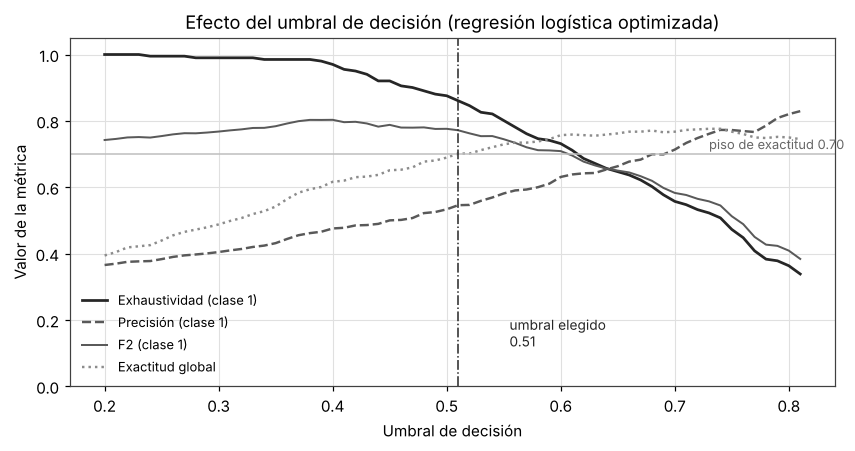

In [40]:
# Figura 10: cómo se mueven las métricas al desplazar el umbral de la regresión logística.
barrido_rl = barridos["Regresión logística"]
u_elegido = umbrales_elegidos["Regresión logística"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(barrido_rl["umbral"], barrido_rl["exhaustividad"], "-", color=NEGRO,
        linewidth=1.8, label="Exhaustividad (clase 1)")
ax.plot(barrido_rl["umbral"], barrido_rl["precisión"], "--", color=GRIS_OSCURO,
        linewidth=1.6, label="Precisión (clase 1)")
ax.plot(barrido_rl["umbral"], barrido_rl["F2"], "-", color=GRIS_OSCURO,
        linewidth=1.3, label="F2 (clase 1)")
ax.plot(barrido_rl["umbral"], barrido_rl["exactitud"], ":", color="0.55",
        linewidth=1.6, label="Exactitud global")
ax.axhline(PISO_EXACTITUD, color="0.75", linewidth=1.0)
ax.axvline(u_elegido, color=NEGRO, linewidth=1.0, linestyle="-.")
ax.annotate(f"umbral elegido\n{u_elegido:.2f}", xy=(u_elegido, 0.12),
            xytext=(u_elegido + 0.045, 0.12), fontsize=9, color=NEGRO)
ax.annotate("piso de exactitud 0.70", xy=(0.73, PISO_EXACTITUD + 0.015), fontsize=8.5,
            color="0.4")
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Valor de la métrica")
ax.set_title("Efecto del umbral de decisión (regresión logística optimizada)")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
plt.tight_layout()
plt.show()

**Figura 10. Efecto del umbral de decisión.**

**Interpretación.** La figura muestra por qué hacía falta la restricción. Bajando el umbral la
exhaustividad sube hasta casi 1.0, pero la precisión y la exactitud caen con ella, y el F2 alcanza
su máximo en 0.40, en una zona donde la exactitud ya está en 0.616. Con el piso de 0.70 el umbral
elegido queda en **0.51**.

Y ese resultado, que a primera vista parece decepcionante, es el hallazgo de esta sección: 0.51
es prácticamente el 0.5 por defecto, y de hecho queda un punto **por encima**. **El umbral no era
el problema.** Una vez que la búsqueda de hiperparámetros encontró la ponderación de clases
adecuada, el punto de corte por defecto ya estaba donde debía estar; la ponderación y el umbral
son dos maneras de accionar la misma palanca, y ajustada una, la otra no tenía nada que aportar.
De hecho el piso de exactitud terminó empujando el umbral ligeramente hacia arriba: en 0.50 la
exactitud por validación cruzada es 0.689 y en 0.51 pasa a 0.701. Lo correcto era comprobarlo en
lugar de suponerlo, y queda comprobado.

El árbol merece una nota aparte: su umbral sale en 0.57 pero produce exactamente las mismas
predicciones que 0.50. Con profundidad 3 y un mínimo de 10 pacientes por hoja, el modelo solo
puede emitir un puñado de probabilidades distintas —una por hoja—, de modo que mover el umbral
dentro del hueco entre dos de esos valores no cambia nada. Es una limitación de los árboles poco
profundos que conviene conocer antes de intentar afinarlos por esta vía.

### 9.5. Comparación antes y después

Aquí es donde el conjunto de prueba entra por primera y única vez. Los tres modelos optimizados
se evalúan en su punto de operación elegido, junto al modelo del segundo corte sin modificar.

In [41]:
# Evaluación sobre el conjunto de prueba. Primera y única vez que se usa en este corte.
def evaluar(nombre, pipe, umbral):
    prob_te = pipe.predict_proba(X_test)[:, 1]
    pred_te = (prob_te >= umbral).astype(int)
    pred_tr = (pipe.predict_proba(X_train)[:, 1] >= umbral).astype(int)
    f1_tr, f1_te = f1_score(y_train, pred_tr), f1_score(y_test, pred_te)
    vn, fp, fn, vp = confusion_matrix(y_test, pred_te).ravel()
    return {"modelo": nombre, "umbral": umbral,
            "exactitud": round(accuracy_score(y_test, pred_te), 3),
            "precisión_1": round(precision_score(y_test, pred_te, zero_division=0), 3),
            "exhaustividad_1": round(recall_score(y_test, pred_te), 3),
            "F1_1": round(f1_te, 3),
            "F2_1": round(fbeta_score(y_test, pred_te, beta=2, zero_division=0), 3),
            "exhaustividad_0": round(recall_score(y_test, pred_te, pos_label=0), 3),
            "AUC": round(roc_auc_score(y_test, prob_te), 3),
            "brecha F1": round(f1_tr - f1_te, 3),
            "VN": vn, "FP": fp, "FN": fn, "VP": vp}

filas = [evaluar(f"{MODELO_2DO_CORTE} (segundo corte)", modelos[MODELO_2DO_CORTE], 0.50)]
for nombre, pipe in mejores_por_familia.items():
    pipe.fit(X_train, y_train)
    filas.append(evaluar(f"{nombre} optimizada", pipe, umbrales_elegidos[nombre]))

# Se añade el punto de operación que el F2 elegiría sin el piso de exactitud, para dejar a la
# vista por qué la restricción de la sección 9.1 hacía falta.
filas.append(evaluar("Reg. logística — F2 sin restricción",
                     mejores_por_familia["Regresión logística"],
                     umbrales_sin_restriccion["Regresión logística"]))

# Tabla 13. Desempeño sobre el conjunto de prueba antes y después de la optimización.
resultados_corte3 = pd.DataFrame(filas).set_index("modelo")
resultados_corte3

,umbral,exactitud,precisión_1,exhaustividad_1,F1_1,F2_1,exhaustividad_0,AUC,brecha F1,VN,FP,FN,VP
modelo,,,,,,,,,,,,,
Reg. logística balanceada (segundo corte),0.50,0.729,0.597,0.687,0.639,0.667,0.752,0.829,0.051,94,31,21,46
Regresión logística optimizada,0.51,0.719,0.561,0.896,0.690,0.800,0.624,0.822,-0.002,78,47,7,60
Árbol de decisión optimizada,0.57,0.714,0.562,0.806,0.663,0.742,0.664,0.763,0.044,83,42,13,54
Bosque aleatorio optimizada,0.44,0.719,0.566,0.836,0.675,0.763,0.656,0.820,0.044,82,43,11,56
Reg. logística — F2 sin restricción,0.40,0.651,0.500,0.955,0.656,0.808,0.488,0.822,-0.013,61,64,3,64


In [42]:
# Tabla 14. El antes y el después del modelo elegido, lado a lado.
MODELO_FINAL = "Regresión logística optimizada"
antes = resultados_corte3.loc[f"{MODELO_2DO_CORTE} (segundo corte)"]
despues = resultados_corte3.loc[MODELO_FINAL]

metricas = ["exactitud", "precisión_1", "exhaustividad_1", "F1_1", "F2_1",
            "exhaustividad_0", "AUC", "brecha F1", "VP", "FN", "FP", "VN"]
antes_despues = pd.DataFrame({
    "segundo corte": [antes[m] for m in metricas],
    "tercer corte": [despues[m] for m in metricas],
})
antes_despues.index = metricas
antes_despues["diferencia"] = (antes_despues["tercer corte"] - antes_despues["segundo corte"]).round(3)
antes_despues

,segundo corte,tercer corte,diferencia
exactitud,0.729,0.719,-0.010
precisión_1,0.597,0.561,-0.036
exhaustividad_1,0.687,0.896,0.209
F1_1,0.639,0.690,0.051
F2_1,0.667,0.800,0.133
exhaustividad_0,0.752,0.624,-0.128
AUC,0.829,0.822,-0.007
brecha F1,0.051,-0.002,-0.053
VP,46.000,60.000,14.000
FN,21.000,7.000,-14.000


**Tabla 13. Desempeño antes y después de la optimización.** · **Tabla 14. El antes y el después
del modelo elegido.**

**Interpretación.** La optimización funcionó, y el cambio está donde debía estar.

**Lo que mejora.** La exhaustividad de la clase positiva pasa de 0.687 a **0.896**. En pacientes:
el modelo detecta 60 de las 67 diabéticas del conjunto de prueba, frente a 46 antes, y los falsos
negativos bajan de 21 a **7**. El F1 de la clase positiva sube de 0.639 a 0.690 y el F2 de 0.667 a
0.800. La brecha de generalización desaparece: de 0.051 pasa a **−0.002**, consecuencia directa
de la regularización fuerte que eligió la búsqueda. El signo negativo no significa que el modelo
rinda mejor sobre datos nuevos que sobre los que vio —eso no tendría sentido—, sino que la
diferencia entre ambos conjuntos es más pequeña que el ruido de medirla sobre 192 registros; lo
que hay que leer es que no queda sobreajuste apreciable. Y la exhaustividad por validación cruzada
confirma que la mejora no es un efecto de esta partición concreta: en el punto de operación
elegido pasa de 0.702 a 0.861.

**Lo que empeora, y hay que decirlo.** La precisión de la clase positiva baja de 0.597 a 0.561, la
exactitud de 0.729 a 0.719 y la exhaustividad de la clase negativa de 0.752 a 0.624. Los falsos
positivos suben de 31 a 47. El AUC queda en 0.822 frente a 0.829, una diferencia de 0.007 que
sobre 192 registros no significa nada —y que de todos modos no podía mejorar por esta vía, porque
el AUC resume el modelo en todos los umbrales y lo que cambiamos fue dónde operar.

**El intercambio.** Catorce pacientes diabéticas más detectadas a cambio de dieciséis consultas de
confirmación adicionales que resultarán negativas. Para un tamizaje el cambio es favorable y por
el mismo argumento que sostiene todo el proyecto: una consulta de más cuesta tiempo médico; una
paciente sin diagnosticar cuesta una enfermedad que avanza. Lo que no sería honesto es presentar
el resultado como una mejora general: el modelo nuevo es mejor **para este propósito**, y es
claramente peor si lo que se quisiera es acertar el mayor número de veces.

**Las dos cifras que activaban la alerta quedan resueltas.** Exactitud 0.719 y métrica principal
0.896, ambas por encima del 0.70. Y conviene señalar que la exactitud quedó justo por encima del
piso porque el piso formaba parte del criterio de selección; no es una coincidencia afortunada,
es una restricción que se cumplió por construcción.

**Las otras dos familias.** El bosque aleatorio optimizado alcanza 0.836 de exhaustividad y, sobre
todo, corrige su sobreajuste: la brecha baja de 0.371 a 0.044 al limitar la profundidad a 3. El
árbol se queda en 0.806. Ninguno supera a la regresión logística en la métrica principal, y la
regresión además sigue siendo la más interpretable de las tres y la que mejor generaliza. Se
mantiene la elección del segundo corte en cuanto a familia de algoritmo; lo que cambió es su
configuración.

### 9.6. El modelo final

In [43]:
# El pipeline que se desplegará, y el umbral con el que opera.
modelo_final = mejores_por_familia["Regresión logística"]
UMBRAL_FINAL = umbrales_elegidos["Regresión logística"]

clf_final = modelo_final.named_steps["clasificador"]
print("Modelo final")
print(f"  pasos del pipeline  : {' → '.join(p[0] for p in modelo_final.steps)}")
print(f"  C (regularización)  : {clf_final.C}  (penalización L2, la de scikit-learn por defecto)")
print(f"  ponderación clases  : {clf_final.class_weight}")
print(f"  umbral de decisión  : {UMBRAL_FINAL}")
print(f"  variables de entrada ({len(X.columns)}):")
for c in X.columns:
    print(f"      {c}")

Modelo final
  pasos del pipeline  : imputacion → escalado → clasificador
  C (regularización)  : 0.01  (penalización L2, la de scikit-learn por defecto)
  ponderación clases  : {0: 1, 1: 3}
  umbral de decisión  : 0.51
  variables de entrada (10):
      pregnancies
      glucose
      blood_pressure
      skin_thickness
      insulin
      bmi
      diabetes_pedigree
      age
      insulin_faltante
      skin_thickness_faltante


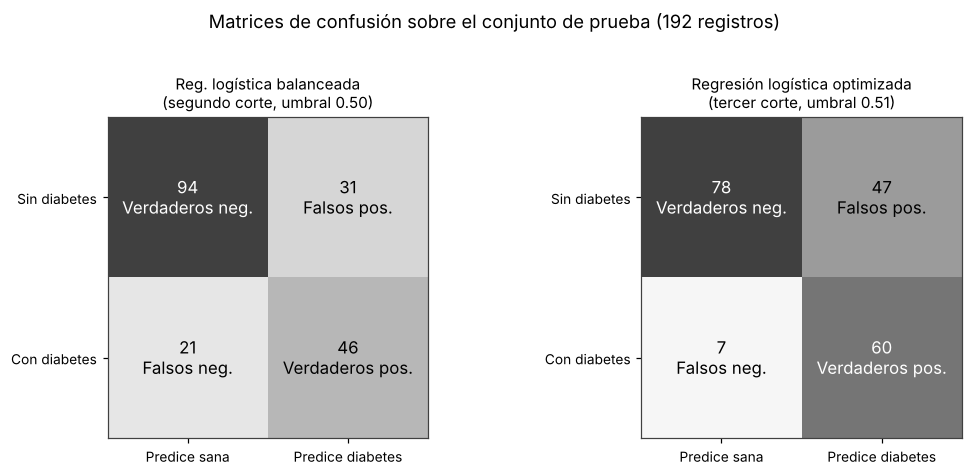

In [44]:
# Figura 11: matriz de confusión antes y después, sobre el mismo conjunto de prueba.
prob_final = modelo_final.predict_proba(X_test)[:, 1]
pred_final = (prob_final >= UMBRAL_FINAL).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (titulo, pred) in zip(axes, [
        (f"{MODELO_2DO_CORTE}\n(segundo corte, umbral 0.50)", predicciones[MODELO_2DO_CORTE]),
        (f"Regresión logística optimizada\n(tercer corte, umbral {UMBRAL_FINAL})", pred_final)]):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.25)
    etiquetas = [["Verdaderos neg.", "Falsos pos."], ["Falsos neg.", "Verdaderos pos."]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{etiquetas[i][j]}", ha="center", va="center",
                    fontsize=11, color="white" if cm[i, j] > cm.max() * 0.7 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Predice sana", "Predice diabetes"], fontsize=9)
    ax.set_yticklabels(["Sin diabetes", "Con diabetes"], fontsize=9)
    ax.set_title(titulo, fontsize=10)
    ax.grid(False)
fig.suptitle("Matrices de confusión sobre el conjunto de prueba (192 registros)", y=1.02)
plt.tight_layout()
plt.show()

In [45]:
# Tabla 15. Coeficientes del modelo final frente a los del segundo corte.
coef_final = pd.Series(modelo_final.named_steps["clasificador"].coef_[0], index=X.columns)
coef_2do = pd.Series(modelos[MODELO_2DO_CORTE].named_steps["clasificador"].coef_[0],
                     index=X.columns)

coeficientes_comparados = pd.DataFrame({
    "segundo corte (C=1)": coef_2do.round(3),
    "tercer corte (C=0.01)": coef_final.round(3),
}).sort_values("tercer corte (C=0.01)", key=abs, ascending=False)
coeficientes_comparados

,segundo corte (C=1),tercer corte (C=0.01)
glucose,1.180,0.634
bmi,0.767,0.386
pregnancies,0.423,0.226
diabetes_pedigree,0.295,0.188
age,0.131,0.163
insulin,0.031,0.146
skin_thickness,-0.081,0.077
insulin_faltante,0.224,0.069
blood_pressure,-0.051,0.067
skin_thickness_faltante,-0.043,0.042


**Figura 11. Matrices de confusión antes y después.** · **Tabla 15. Coeficientes comparados.**

**Interpretación de los coeficientes.** El orden de las cuatro primeras variables se mantiene
—glucosa, índice de masa corporal, embarazos e índice de pedigrí familiar—, de modo que la
respuesta a la primera mitad de la pregunta de investigación no cambia con la optimización. Lo que
cambia es la magnitud: todos los coeficientes se encogen, y el de la glucosa pasa de 1.180 a
0.634. Eso es exactamente lo que hace una regularización fuerte y no debe leerse como que la
glucosa importa menos; los coeficientes siguen siendo comparables entre sí, que es lo que permite
ordenarlos.

Hay un detalle que sí vale la pena mirar. En el segundo corte la insulina tenía un coeficiente
casi nulo, 0.031, y lo explicábamos por su redundancia con la glucosa: con la glucosa en el
modelo, la insulina no aportaba nada nuevo. Con la regularización fuerte su coeficiente sube a
0.146. No es una contradicción, es el comportamiento conocido de la penalización L2 ante
variables correlacionadas: en lugar de dejar que una se lleve todo el peso y la otra quede en
cero, lo reparte entre las dos. La lectura correcta sigue siendo la del segundo corte, que
glucosa e insulina miden en parte lo mismo; lo que el modelo nuevo muestra es que el reparto de
ese peso entre ambas era en buena medida arbitrario.

In [46]:
# Tabla 16. Perfil de los siete falsos negativos que quedan.
resultado_final = X_test.copy()
resultado_final["real"] = y_test
resultado_final["probabilidad"] = prob_final
resultado_final["predicho"] = pred_final

fn_final = resultado_final[(resultado_final["real"] == 1) & (resultado_final["predicho"] == 0)]
vp_final = resultado_final[(resultado_final["real"] == 1) & (resultado_final["predicho"] == 1)]

print(f"Falsos negativos: {len(fn_final)} de {int(y_test.sum())} pacientes diabéticas")
print(f"Probabilidades que les asignó el modelo: "
      f"{', '.join(f'{p:.3f}' for p in sorted(fn_final['probabilidad']))}")
print(f"Umbral de decisión: {UMBRAL_FINAL}\n")

perfil_fn = pd.DataFrame({
    "falsos negativos (mediana)": fn_final[["glucose", "bmi", "age", "insulin"]].median(),
    "detectadas (mediana)": vp_final[["glucose", "bmi", "age", "insulin"]].median(),
}).round(2)
perfil_fn["diferencia"] = (perfil_fn.iloc[:, 1] - perfil_fn.iloc[:, 0]).round(2)
perfil_fn

Falsos negativos: 7 de 67 pacientes diabéticas
Probabilidades que les asignó el modelo: 0.209, 0.386, 0.400, 0.432, 0.455, 0.457, 0.488
Umbral de decisión: 0.51



,falsos negativos (mediana),detectadas (mediana),diferencia
glucose,107.0,141.5,34.5
bmi,29.6,34.3,4.7
age,28.0,35.0,7.0
insulin,88.0,190.5,102.5


**Tabla 16. Perfil de los falsos negativos del modelo final.**

**Interpretación.** Quedan siete pacientes diabéticas sin detectar, y seis de las siete recibieron
una probabilidad de entre 0.386 y 0.488, es decir a menos de 0.13 del umbral. No son errores
groseros del modelo: son pacientes que cayeron del lado equivocado de una frontera que pasa muy
cerca de ellas. Solo una, con probabilidad 0.209, queda claramente mal clasificada.

El perfil confirma lo que ya mostraba el segundo corte: las que se escapan tienen una glucosa
mediana de 107.0 mg/dL frente a 141.5 en las detectadas, y una insulina mediana de 88.0 frente a
190.5. El modelo falla justo en la zona donde las dos poblaciones se solapan y donde ninguna de
las variables disponibles alcanza para separarlas. Bajar más el umbral las recuperaría, a costa
de los falsos positivos y de la exactitud, que es precisamente el intercambio que el criterio de
la sección 9.1 ya resolvió.

## 10. Serialización del pipeline para la aplicación

La aplicación no debe entrenar nada. Tiene que cargar el pipeline ya ajustado —con la imputación y
el escalamiento dentro— y limitarse a pedirle predicciones. Eso se consigue guardándolo con
`joblib`.

Lo que se guarda no es solo el pipeline. Un modelo suelto en un archivo es una fuente de errores:
quien lo cargue no sabe en qué orden espera las variables, con qué umbral opera ni con qué
versión de las librerías se creó. Así que el archivo contiene un paquete con todo lo que la
aplicación necesita para funcionar sin volver a mirar este cuaderno:

| Clave | Contenido |
|---|---|
| `pipeline` | El `Pipeline` ajustado: imputación por mediana, escalamiento y regresión logística |
| `umbral` | El punto de corte elegido en la sección 9.4 |
| `columnas` | El orden exacto de las diez variables de entrada |
| `variables` | Etiqueta, unidad, rango válido y valor por defecto de cada campo del formulario |
| `metricas_prueba` | Las métricas de la Tabla 13, para que la aplicación no las recalcule mal |
| `casos_verificacion` | Los registros con los que se comprueba la paridad con el cuaderno |
| `versiones` | Las versiones de Python y de las librerías con que se creó el archivo |

La aplicación lee de aquí hasta las etiquetas del formulario, de modo que este cuaderno queda como
única fuente de verdad: si mañana cambia una variable o un rango, se cambia en un solo sitio.

In [47]:
# Metadatos de cada campo del formulario. Los rangos combinan el recorrido observado en el
# conjunto de datos con lo clínicamente plausible, por eso son algo más amplios que el dataset.
VARIABLES_FORMULARIO = {
    "pregnancies": {"etiqueta": "Número de embarazos", "unidad": "", "tipo": "entero",
                    "min": 0, "max": 20, "paso": 1, "defecto": 2,
                    "ayuda": "Embarazos previos de la paciente. El valor 0 es válido."},
    "glucose": {"etiqueta": "Glucosa en plasma", "unidad": "mg/dL", "tipo": "decimal",
                "min": 40.0, "max": 300.0, "paso": 1.0, "defecto": 120.0,
                "ayuda": "Medición a las 2 h de una prueba oral de tolerancia a la glucosa."},
    "blood_pressure": {"etiqueta": "Presión arterial diastólica", "unidad": "mm Hg",
                       "tipo": "decimal", "min": 20.0, "max": 140.0, "paso": 1.0,
                       "defecto": 72.0, "ayuda": "Presión diastólica en reposo."},
    "bmi": {"etiqueta": "Índice de masa corporal", "unidad": "kg/m²", "tipo": "decimal",
            "min": 12.0, "max": 70.0, "paso": 0.1, "defecto": 32.0,
            "ayuda": "Peso en kilogramos dividido por el cuadrado de la talla en metros."},
    "diabetes_pedigree": {"etiqueta": "Índice de antecedente familiar", "unidad": "",
                          "tipo": "decimal", "min": 0.0, "max": 3.0, "paso": 0.01,
                          "defecto": 0.37,
                          "ayuda": "Índice del estudio original; resume los antecedentes "
                                   "familiares de diabetes. En el conjunto va de 0.078 a 2.42."},
    "age": {"etiqueta": "Edad", "unidad": "años", "tipo": "entero",
            "min": 21, "max": 100, "paso": 1, "defecto": 33,
            "ayuda": "El conjunto solo incluye mujeres de 21 años o más."},
    "skin_thickness": {"etiqueta": "Espesor del pliegue cutáneo del tríceps", "unidad": "mm",
                       "tipo": "decimal", "min": 5.0, "max": 110.0, "paso": 1.0,
                       "defecto": 29.0, "opcional": True,
                       "ayuda": "Si no se tomó la medición, deje la casilla sin marcar: el "
                                "modelo fue entrenado para trabajar con ese dato ausente."},
    "insulin": {"etiqueta": "Insulina sérica", "unidad": "mu U/ml", "tipo": "decimal",
                "min": 10.0, "max": 900.0, "paso": 1.0, "defecto": 155.0, "opcional": True,
                "ayuda": "Medición a las 2 h. Falta en el 48.70 % de los registros del "
                         "conjunto, así que el modelo contempla su ausencia."},
}

# Comprobación de que no se quedó ninguna variable por fuera ni sobra ninguna.
esperadas = set(X.columns) - {"insulin_faltante", "skin_thickness_faltante"}
assert set(VARIABLES_FORMULARIO) == esperadas, (
    f"Descuadre entre el formulario y el modelo: "
    f"faltan {esperadas - set(VARIABLES_FORMULARIO)}, "
    f"sobran {set(VARIABLES_FORMULARIO) - esperadas}")
print(f"{len(VARIABLES_FORMULARIO)} campos en el formulario; "
      f"los 2 marcadores de ausencia se derivan de las casillas de 'no se tomó la medición'.")

8 campos en el formulario; los 2 marcadores de ausencia se derivan de las casillas de 'no se tomó la medición'.


In [48]:
# Dos registros reales del conjunto de prueba, para comprobar que la aplicación devuelve
# exactamente lo mismo que este cuaderno. Se eligen los dos extremos de probabilidad.
orden = resultado_final.sort_values("probabilidad")
casos_verificacion = []
for etiqueta, fila in [("probabilidad más baja del conjunto de prueba", orden.iloc[0]),
                       ("probabilidad más alta del conjunto de prueba", orden.iloc[-1])]:
    casos_verificacion.append({
        "descripcion": etiqueta,
        "indice_original": int(fila.name),
        "entrada": {c: (None if pd.isna(fila[c]) else float(fila[c]))
                    for c in VARIABLES_FORMULARIO},
        "probabilidad": round(float(fila["probabilidad"]), 6),
        "prediccion": int(fila["predicho"]),
        "diagnostico_real": int(fila["real"]),
    })

for caso in casos_verificacion:
    print(f"Registro {caso['indice_original']} — {caso['descripcion']}")
    print(f"  entrada      : {caso['entrada']}")
    print(f"  probabilidad : {caso['probabilidad']:.6f}")
    print(f"  predicción   : {caso['prediccion']}   diagnóstico real: {caso['diagnostico_real']}")

Registro 617 — probabilidad más baja del conjunto de prueba
  entrada      : {'pregnancies': 2.0, 'glucose': 68.0, 'blood_pressure': 62.0, 'bmi': 20.1, 'diabetes_pedigree': 0.257, 'age': 23.0, 'skin_thickness': 13.0, 'insulin': 15.0}
  probabilidad : 0.075587
  predicción   : 0   diagnóstico real: 0
Registro 445 — probabilidad más alta del conjunto de prueba
  entrada      : {'pregnancies': 0.0, 'glucose': 180.0, 'blood_pressure': 78.0, 'bmi': 59.4, 'diabetes_pedigree': 2.42, 'age': 25.0, 'skin_thickness': 63.0, 'insulin': 14.0}
  probabilidad : 0.976880
  predicción   : 1   diagnóstico real: 1


In [49]:
# Paquete que se guarda con joblib.
os.makedirs("modelo", exist_ok=True)
os.makedirs("datos", exist_ok=True)

clasificador_final = modelo_final.named_steps["clasificador"]
vn_f, fp_f, fn_f, vp_f = confusion_matrix(y_test, pred_final).ravel()

paquete = {
    "pipeline": modelo_final,
    "umbral": UMBRAL_FINAL,
    "columnas": list(X.columns),
    "variables": VARIABLES_FORMULARIO,
    "nombre_modelo": "Regresión logística con regularización L2 y ponderación de clases 3:1",
    "hiperparametros": {"C": clasificador_final.C,
                        "class_weight": clasificador_final.class_weight,
                        "regularizacion": "L2 (la de scikit-learn por defecto)"},
    "imputacion": "mediana, ajustada solo con los datos de entrenamiento",
    "metricas_prueba": {
        "n_prueba": int(len(y_test)), "n_positivos": int(y_test.sum()),
        "exactitud": round(accuracy_score(y_test, pred_final), 3),
        "precision_1": round(precision_score(y_test, pred_final, zero_division=0), 3),
        "exhaustividad_1": round(recall_score(y_test, pred_final), 3),
        "f1_1": round(f1_score(y_test, pred_final), 3),
        "f2_1": round(fbeta_score(y_test, pred_final, beta=2, zero_division=0), 3),
        "exhaustividad_0": round(recall_score(y_test, pred_final, pos_label=0), 3),
        "auc": round(roc_auc_score(y_test, prob_final), 3),
        "matriz_confusion": [[int(vn_f), int(fp_f)], [int(fn_f), int(vp_f)]],
    },
    "metricas_segundo_corte": {
        "exactitud": 0.729, "precision_1": 0.597, "exhaustividad_1": 0.687,
        "f1_1": 0.639, "auc": 0.829, "matriz_confusion": [[94, 31], [21, 46]],
    },
    "casos_verificacion": casos_verificacion,
    "semilla": SEMILLA,
    "fecha_entrenamiento": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__,
                  "joblib": joblib.__version__},
}

RUTA_MODELO = "modelo/pipeline_diabetes.joblib"
joblib.dump(paquete, RUTA_MODELO, compress=3)
print(f"Guardado: {RUTA_MODELO}  ({os.path.getsize(RUTA_MODELO) / 1024:.1f} KB)")
print(f"Versiones registradas: {paquete['versiones']}")

Guardado: modelo/pipeline_diabetes.joblib  (3.0 KB)
Versiones registradas: {'python': '3.13.18', 'scikit-learn': '1.9.1', 'pandas': '3.0.5', 'numpy': '2.5.3', 'joblib': '1.6.0'}


In [50]:
# El conjunto preparado, con la partición marcada. La aplicación lo usa para las gráficas del
# análisis exploratorio y para recalcular las métricas con el pipeline cargado, nunca para
# entrenar. Se guardan los NaN tal cual: la imputación pertenece al pipeline.
preparado = X.copy()
preparado["outcome"] = y
preparado["particion"] = "entrenamiento"
preparado.loc[X_test.index, "particion"] = "prueba"

RUTA_DATOS = "datos/diabetes_preparado.csv"
preparado.to_csv(RUTA_DATOS, index=False)

print(f"Guardado: {RUTA_DATOS}")
print(f"  {preparado.shape[0]} filas × {preparado.shape[1]} columnas")
print(preparado["particion"].value_counts().to_string())
print(f"  faltantes conservados como NaN: {int(preparado.isnull().sum().sum())}")

Guardado: datos/diabetes_preparado.csv
  768 filas × 12 columnas
particion
entrenamiento    576
prueba           192
  faltantes conservados como NaN: 652


## 11. Verificación: la aplicación tiene que coincidir con el cuaderno

La guía pide comprobar que, para un mismo registro, la predicción de Streamlit sea la misma que la
del cuaderno. Esa comprobación puede fallar por motivos que no tienen nada que ver con el modelo:
un orden de columnas distinto, un marcador de ausencia mal derivado, un redondeo en el
formulario. Vale la pena dejarla automatizada.

La celda siguiente simula lo que hará la aplicación: toma el paquete recién guardado, reconstruye
la fila de entrada a partir de los valores del formulario —derivando los dos marcadores de
ausencia como se hizo al entrenar— y compara el resultado con el que este cuaderno calculó.

In [51]:
# Esta función es la misma lógica que usa app.py para armar la fila de entrada.
def construir_fila(entrada, columnas):
    '''Convierte los valores del formulario en la fila que espera el pipeline.

    Un campo en None significa que la medición no se tomó: se deja como NaN y el marcador
    de ausencia correspondiente se pone en 1, igual que en el entrenamiento.
    '''
    fila = {c: np.nan for c in columnas}
    for campo, valor in entrada.items():
        fila[campo] = np.nan if valor is None else float(valor)
    fila["insulin_faltante"] = int(pd.isna(fila["insulin"]))
    fila["skin_thickness_faltante"] = int(pd.isna(fila["skin_thickness"]))
    return pd.DataFrame([[fila[c] for c in columnas]], columns=columnas)


# Se recarga el archivo desde el disco, para probar lo que realmente va al repositorio.
paquete_cargado = joblib.load(RUTA_MODELO)
pipeline_cargado = paquete_cargado["pipeline"]
umbral_cargado = paquete_cargado["umbral"]

print("Verificación de paridad cuaderno ↔ aplicación\n")
todo_bien = True
for caso in paquete_cargado["casos_verificacion"]:
    fila = construir_fila(caso["entrada"], paquete_cargado["columnas"])
    prob = float(pipeline_cargado.predict_proba(fila)[0, 1])
    pred = int(prob >= umbral_cargado)
    coincide = abs(prob - caso["probabilidad"]) < 1e-6 and pred == caso["prediccion"]
    todo_bien &= coincide
    print(f"Registro {caso['indice_original']}")
    print(f"  cuaderno   : probabilidad {caso['probabilidad']:.6f} → clase {caso['prediccion']}")
    print(f"  recargado  : probabilidad {prob:.6f} → clase {pred}")
    print(f"  {'coincide' if coincide else 'NO COINCIDE'}\n")

assert todo_bien, "El modelo serializado no reproduce las predicciones del cuaderno."
print("El pipeline guardado reproduce las predicciones del cuaderno.")

Verificación de paridad cuaderno ↔ aplicación

Registro 617
  cuaderno   : probabilidad 0.075587 → clase 0
  recargado  : probabilidad 0.075587 → clase 0
  coincide

Registro 445
  cuaderno   : probabilidad 0.976880 → clase 1
  recargado  : probabilidad 0.976880 → clase 1
  coincide

El pipeline guardado reproduce las predicciones del cuaderno.


In [52]:
# Prueba 2 de la guía: un caso normal construido a mano, con los valores por defecto del
# formulario, y el mismo caso declarando que no se tomaron los dos exámenes opcionales.
caso_normal = {c: VARIABLES_FORMULARIO[c]["defecto"] for c in VARIABLES_FORMULARIO}
caso_sin_examenes = dict(caso_normal, insulin=None, skin_thickness=None)

for etiqueta, entrada in [("Caso normal (todos los exámenes)", caso_normal),
                          ("Mismo caso sin insulina ni pliegue cutáneo", caso_sin_examenes)]:
    fila = construir_fila(entrada, paquete_cargado["columnas"])
    prob = float(pipeline_cargado.predict_proba(fila)[0, 1])
    print(f"{etiqueta}")
    print(f"  marcadores de ausencia: insulina={int(fila['insulin_faltante'].iloc[0])}, "
          f"pliegue={int(fila['skin_thickness_faltante'].iloc[0])}")
    print(f"  probabilidad {prob:.4f} → "
          f"{'riesgo alto' if prob >= umbral_cargado else 'riesgo bajo'} "
          f"(umbral {umbral_cargado})\n")

Caso normal (todos los exámenes)
  marcadores de ausencia: insulina=0, pliegue=0
  probabilidad 0.4823 → riesgo bajo (umbral 0.51)

Mismo caso sin insulina ni pliegue cutáneo
  marcadores de ausencia: insulina=1, pliegue=1
  probabilidad 0.5263 → riesgo alto (umbral 0.51)



In [53]:
# Prueba 3 de la guía: entradas inválidas. Esta es la misma validación que corre en app.py,
# para que el cuaderno deje constancia de qué rechaza el formulario y por qué.
def validar_entrada(entrada, variables):
    '''Devuelve la lista de errores de una entrada del formulario. Vacía si todo está bien.'''
    errores = []
    for campo, meta in variables.items():
        valor = entrada.get(campo, None)
        if valor is None:
            if not meta.get("opcional", False):
                errores.append(f"{meta['etiqueta']}: es un campo obligatorio.")
            continue
        try:
            numero = float(valor)
        except (TypeError, ValueError):
            errores.append(f"{meta['etiqueta']}: se esperaba un número.")
            continue
        if np.isnan(numero):
            errores.append(f"{meta['etiqueta']}: se esperaba un número.")
            continue
        if meta["tipo"] == "entero" and numero != int(numero):
            errores.append(f"{meta['etiqueta']}: debe ser un número entero.")
        if not (meta["min"] <= numero <= meta["max"]):
            unidad = f" {meta['unidad']}" if meta["unidad"] else ""
            errores.append(f"{meta['etiqueta']}: {numero:g}{unidad} está fuera del rango "
                           f"admitido ({meta['min']:g} a {meta['max']:g}{unidad}).")
    return errores


pruebas_invalidas = [
    ("Glucosa fuera de rango", dict(caso_normal, glucose=12)),
    ("Edad por debajo del mínimo del conjunto", dict(caso_normal, age=8)),
    ("Embarazos con decimales", dict(caso_normal, pregnancies=2.5)),
    ("Presión negativa y texto en el IMC", dict(caso_normal, blood_pressure=-70, bmi="treinta")),
    ("Campo obligatorio vacío", dict(caso_normal, glucose=None)),
    ("Caso normal (control)", caso_normal),
]

for etiqueta, entrada in pruebas_invalidas:
    errores = validar_entrada(entrada, VARIABLES_FORMULARIO)
    print(f"{etiqueta}")
    if errores:
        for e in errores:
            print(f"  rechazado → {e}")
    else:
        print("  aceptado, el formulario permite predecir")
    print()

Glucosa fuera de rango
  rechazado → Glucosa en plasma: 12 mg/dL está fuera del rango admitido (40 a 300 mg/dL).

Edad por debajo del mínimo del conjunto
  rechazado → Edad: 8 años está fuera del rango admitido (21 a 100 años).

Embarazos con decimales
  rechazado → Número de embarazos: debe ser un número entero.

Presión negativa y texto en el IMC
  rechazado → Presión arterial diastólica: -70 mm Hg está fuera del rango admitido (20 a 140 mm Hg).
  rechazado → Índice de masa corporal: se esperaba un número.

Campo obligatorio vacío
  rechazado → Glucosa en plasma: es un campo obligatorio.

Caso normal (control)
  aceptado, el formulario permite predecir



## 12. Archivos que van al repositorio

El último paso del cuaderno es dejar listos los archivos que el repositorio necesita. Dos de
ellos ya están guardados; falta `requirements.txt`, y conviene generarlo desde aquí en lugar de
escribirlo a mano.

La razón es concreta. Un archivo creado con `joblib` guarda objetos de scikit-learn tal como los
construyó la versión que lo creó; si la aplicación los carga con otra versión, en el mejor de los
casos aparece una advertencia y en el peor falla. Generando `requirements.txt` en la misma
ejecución que produce el modelo, las versiones de los dos archivos nunca se separan.

In [54]:
# requirements.txt generado con las versiones de ESTA ejecución, las mismas con las que se
# construyó el archivo .joblib. Si el cuaderno se vuelve a ejecutar en otro entorno, este
# archivo se actualiza con él y el par sigue siendo coherente.
VERSION_STREAMLIT = "1.67.0"   # versión con la que se probó la aplicación

requisitos = [
    f"streamlit=={VERSION_STREAMLIT}",
    f"scikit-learn=={sklearn.__version__}",
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"joblib=={joblib.__version__}",
]
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(requisitos) + "\n")

print("requirements.txt")
print("-" * 30)
print("\n".join(requisitos))
print()
print("Archivos generados por este cuaderno:")
for ruta in ["modelo/pipeline_diabetes.joblib", "datos/diabetes_preparado.csv",
             "requirements.txt"]:
    print(f"  {ruta:40s} {os.path.getsize(ruta) / 1024:8.1f} KB")

requirements.txt
------------------------------
streamlit==1.67.0
scikit-learn==1.9.1
pandas==3.0.5
numpy==2.5.3
matplotlib==3.11.2
joblib==1.6.0

Archivos generados por este cuaderno:
  modelo/pipeline_diabetes.joblib               3.0 KB
  datos/diabetes_preparado.csv                 39.1 KB
  requirements.txt                              0.1 KB


## 13. Conclusiones del tercer corte

**Qué se revisó.** Las treinta métricas de la Tabla 5 del segundo informe se reprodujeron sin
diferencias, de modo que el punto de partida estaba bien medido. Lo que estaba mal era el punto de
operación: con una exhaustividad de 0.687 sobre la clase positiva, el modelo quedaba por debajo
del piso de 0.70 que fija la guía justamente en la métrica que el proyecto había declarado como
principal.

**Qué se cambió.** Tres cosas, y solo una de las tres sirvió.

1. **La estrategia de imputación no era el problema.** La imputación por vecinos más cercanos
   mejora el F2 en 0.013 con una desviación entre particiones de 0.073, así que la ventaja cabe
   dentro del ruido. Se conservó la mediana.
2. **Los hiperparámetros sí lo eran.** La búsqueda por rejilla eligió, en las tres familias de
   algoritmos, modelos más simples y con una ponderación explícita a favor de la clase positiva.
   En la regresión logística: `C = 0.01` con penalización L2 y pesos de 3 a 1. De aquí vino toda la
   mejora.
3. **El umbral tampoco era el problema.** El barrido lo situó en 0.51, es decir donde ya estaba por
   defecto. La ponderación de clases y el umbral accionan la misma palanca, y ajustada la primera,
   el segundo no tenía nada que aportar. Era una comprobación necesaria, no un ajuste.

**Qué resultado se obtuvo.** La regresión logística optimizada detecta **60 de las 67** pacientes
diabéticas del conjunto de prueba, frente a 46 del modelo anterior; los falsos negativos bajan de
21 a 7. La exhaustividad de la clase positiva pasa de 0.687 a 0.896, el F1 de 0.639 a 0.690 y la
brecha de generalización de 0.051 a cero. El precio son dieciséis falsos positivos más, una
precisión que baja de 0.597 a 0.561 y una exactitud que baja un punto, de 0.729 a 0.719. Para un
tamizaje el intercambio es favorable; presentarlo como una mejora general no sería honesto.

**Qué sigue en pie de las limitaciones.** Todas las del segundo corte, porque ninguna dependía del
modelo. El conjunto tiene 768 registros y el de prueba 192, de modo que el movimiento de dos o
tres pacientes todavía desplaza las métricas varios puntos: con siete falsos negativos, uno más o
uno menos cambia la exhaustividad en 1.5 puntos. Los datos corresponden solo a mujeres mayores de
21 años de una comunidad indígena y no se extrapolan a otras poblaciones. Casi la mitad de los
valores de insulina sigue ausente. La fuga residual del análisis exploratorio sigue declarada. Y
se añade una limitación nueva de este corte: el umbral y los hiperparámetros se eligieron con
validación cruzada sobre 576 registros, un conjunto pequeño para optimizar, de modo que parte de
la ganancia podría no sostenerse sobre datos nuevos. Que la exhaustividad por validación cruzada
(0.861) y la de prueba (0.896) apunten en la misma dirección es tranquilizador, pero no es una
garantía.

**El alcance de lo entregado.** La aplicación que acompaña a este cuaderno es un prototipo
académico. Un modelo que deja pasar 7 de cada 67 pacientes diabéticas y que envía a confirmación
a 47 de cada 125 sanas no es utilizable para decidir sobre una persona, y así queda advertido en
la propia aplicación. Lo que el ejercicio sí demuestra es el ciclo completo: datos sucios
diagnosticados y corregidos, un modelo elegido con un criterio explícito y defendible, optimizado
sin mirar el conjunto de prueba, serializado y puesto a funcionar detrás de una interfaz donde
cualquiera puede comprobar qué predice y por qué.